# Лабораторная работа №3. Кластеризация данных
### Отчёт по практическому заданию курса «Машинное обучение»

## 1. Введение
**Цель работы:** исследовать сегментацию смартфонов по аппаратным характеристикам,
сопоставить K-Means и EM (Gaussian Mixture), оценить качество и объяснить полученные группы.

**Постановка задачи:**

1. Описать данные, распределения, пропуски, повторные строки и выбросы.
2. Обосновать набор признаков и проверить избыточность и кластерную тенденцию.
3. Сравнить способы масштабирования и рассмотреть парные распределения.
4. Исследовать число групп по локтю, силуэту и дендрограмме.
5. Обучить два метода и сравнить внутренние, геометрические и внешние метрики.
6. Проверить чувствительность к параметрам и составить физические портреты центров.

**Датасет:** Mobile Price Classification, одно наблюдение — один смартфон.

При обучении без учителя алгоритм не получает правильные ценовые классы, в отличие
от классификации. Гипотеза: четыре группы характеристик могут частично восстановить
скрытые ценовые сегменты. Это проверяемая гипотеза, а не гарантированный результат.

План: описание данных → предобработка → выбор числа групп → обучение и метрики →
исследование параметров → визуализация и профили → заключение → источники.
Четыре кластера рассматриваются как исследовательская модель технической сегментации;
оптимальное k оценивается независимо по внутренним метрикам.
Ценовые метки не определяют признаки и параметры.

In [1]:
import os
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[name] = '1'
import random
import warnings
warnings.filterwarnings('ignore')
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from IPython.display import display
from scipy.stats import shapiro, zscore
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score, pairwise_distances,
    adjusted_rand_score, rand_score, jaccard_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score, confusion_matrix)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='Set2', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11})
analysis = {}
FEATURE_LABELS = {
    'ram': 'ОЗУ, МБ', 'battery_power': 'Батарея, мАч',
    'px_height': 'Высота изображения, px', 'px_width': 'Ширина изображения, px',
    'int_memory': 'Встроенная память, ГБ', 'mobile_wt': 'Масса, г',
    'talk_time': 'Время разговора, ч', 'blue': 'Bluetooth', 'dual_sim': 'Две SIM-карты',
    'four_g': 'Поддержка 4G', 'three_g': 'Поддержка 3G',
    'touch_screen': 'Сенсорный экран', 'wifi': 'Wi-Fi',
    'clock_speed': 'Частота процессора, ГГц', 'm_dep': 'Толщина, см',
    'n_cores': 'Число ядер', 'fc': 'Фронтальная камера, Мп',
    'pc': 'Основная камера, Мп', 'sc_h': 'Высота экрана, см', 'sc_w': 'Ширина экрана, см',
}

analysis['setup'] = (f'### Пояснение к подготовке окружения\n\n'
    f'Используется Python {platform.python_version()}, scikit-learn {sklearn.__version__}. '
    f'Начальное состояние генераторов зафиксировано числом {RANDOM_STATE}. Это позволяет '
    'повторить начальные центры K-Means, запуски EM и случайные выборки для проверки Хопкинса. '
    'Внешние ценовые классы на этом этапе не нужны.\n\n'
    'В кодовую ячейку включены две вспомогательные процедуры: Hopkins сравнивает расстояния до соседей '
    'с равномерным контролем, а венгерский алгоритм сопоставляет произвольные номера '
    'кластеров с эталонными метками только при внешней оценке. Их наличие не означает '
    'использование цен при обучении.')

"""Численные процедуры, независимые от эталонных ценовых классов."""
import numpy as np
from scipy.optimize import linear_sum_assignment
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.cluster import contingency_matrix


def hopkins(X, sample_size=200, random_state=42, power=None):
    """H=sum(u**d)/(sum(u**d)+sum(w**d)); H≈0.5 для uniform.

    u: расстояния uniform-точек до выборки, w: до другого наблюдения.
    Степень d учитывает объём d-мерного шара; power=1 — диагностика
    часто используемой альтернативной конвенции. Нулевые соседи самого
    наблюдения исключаются запросом k=2. Дубликаты не удаляются молча.
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) < 3 or not np.isfinite(X).all():
        raise ValueError("Нужна конечная двумерная матрица минимум из 3 строк")
    if np.any(np.ptp(X, axis=0) == 0):
        raise ValueError("Перед Hopkins исключите постоянные признаки")
    rng = np.random.default_rng(random_state)
    size = min(sample_size, len(X))
    indices = rng.choice(len(X), size=size, replace=False)
    uniform = rng.uniform(X.min(axis=0), X.max(axis=0), (size, X.shape[1]))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    u = nn.kneighbors(uniform, n_neighbors=1)[0][:, 0]
    w = nn.kneighbors(X[indices], n_neighbors=2)[0][:, 1]
    exponent = X.shape[1] if power is None else power
    scale = max(u.max(), w.max())
    if scale == 0:
        raise ValueError("Все расстояния равны нулю")
    a, b = np.sum((u / scale) ** exponent), np.sum((w / scale) ** exponent)
    return float(a / (a + b))


def align_labels(y_true, labels):
    """Венгерское сопоставление, максимизирующее число совпадений.

    Оптимальность относится к accuracy, а не непосредственно к macro Jaccard.
    Лишние кластеры получают метку -1, а не сливаются с известными классами.
    """
    y_true, labels = np.asarray(y_true), np.asarray(labels)
    classes, clusters = np.unique(y_true), np.unique(labels)
    matrix = contingency_matrix(y_true, labels)
    rows, cols = linear_sum_assignment(-matrix)
    mapping = {clusters[c]: classes[r] for r, c in zip(rows, cols)}
    return np.array([mapping.get(c, -1) for c in labels]), mapping


### Пояснение к подготовке окружения

Используется Python 3.13.2, scikit-learn 1.9.1. Начальное состояние генераторов зафиксировано числом 42. Это позволяет повторить начальные центры K-Means, запуски EM и случайные выборки для проверки Хопкинса. Внешние ценовые классы на этом этапе не нужны.

В кодовую ячейку включены две вспомогательные процедуры: Hopkins сравнивает расстояния до соседей с равномерным контролем, а венгерский алгоритм сопоставляет произвольные номера кластеров с эталонными метками только при внешней оценке. Их наличие не означает использование цен при обучении.

## 2. Описание датасета и дескриптивный анализ

In [2]:
dataset_path = kagglehub.dataset_download('iabhishekofficial/mobile-price-classification')
csv_path = Path(dataset_path) / 'train.csv'
df = pd.read_csv(csv_path)
y_true = df['price_range'].copy()
X_raw = df.drop(columns=['price_range'])
assert X_raw.shape == (2000, 20), f'Неожиданная размерность: {X_raw.shape}'
assert 'price_range' not in X_raw
assert all(pd.api.types.is_numeric_dtype(t) for t in X_raw.dtypes)
assert np.isfinite(X_raw.to_numpy()).all(), 'Найдены пропуски/бесконечные значения'
X_raw.info()
display(X_raw.head())

analysis['data_load'] = (f'### Пояснение к датасету\n\n'
    f'В файле {len(df)} строк и {df.shape[1]} столбец. Из них {X_raw.shape[1]} описывают '
    'аппаратные характеристики смартфона: память, экран, батарею, камеры и поддержку функций. '
    'Одна строка соответствует одному устройству. Первые пять строк позволяют проверить, '
    'что таблица прочитана с заголовками и числа не превратились в текст.\n\n'
    f'Суммарно пропусков {int(X_raw.isna().sum().sum())}, повторных векторов характеристик '
    f'{int(X_raw.duplicated().sum())}. Рабочая матрица содержит только числовые значения. '
    'Столбец price_range сразу сохранён отдельно: он не входит в описываемые расстояния, '
    'масштабирование, выбор признаков и обучение. Проверка того, похожи ли технические '
    'группы на ценовые классы, появится после обучения моделей.')

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0


### Пояснение к датасету

В файле 2000 строк и 21 столбец. Из них 20 описывают аппаратные характеристики смартфона: память, экран, батарею, камеры и поддержку функций. Одна строка соответствует одному устройству. Первые пять строк позволяют проверить, что таблица прочитана с заголовками и числа не превратились в текст.

Суммарно пропусков 0, повторных векторов характеристик 0. Рабочая матрица содержит только числовые значения. Столбец price_range сразу сохранён отдельно: он не входит в описываемые расстояния, масштабирование, выбор признаков и обучение. Проверка того, похожи ли технические группы на ценовые классы, появится после обучения моделей.

In [3]:
stats = X_raw.describe().T
stats['skew'] = X_raw.skew()
stats['kurtosis'] = X_raw.kurtosis()
stats['variance'] = X_raw.var()
stats['CV'] = X_raw.std() / X_raw.mean().replace(0, np.nan)
display(stats.rename(index=FEATURE_LABELS))
missing = int(X_raw.isna().sum().sum())
duplicates = int(X_raw.duplicated().sum())

analysis['data'] = (f'### Пояснение к описательным статистикам\n\n'
    f'ОЗУ лежит в диапазоне {X_raw.ram.min()}–{X_raw.ram.max()} МБ; среднее '
    f'{X_raw.ram.mean():.1f} МБ, стандартное отклонение {X_raw.ram.std():.1f} МБ. '
    f'Батарея: {X_raw.battery_power.min()}–{X_raw.battery_power.max()} мАч, '
    f'среднее {X_raw.battery_power.mean():.1f} мАч. Продолжительность разговора '
    f'{X_raw.talk_time.min()}–{X_raw.talk_time.max()} часов. Поэтому сырые расстояния '
    'между устройствами заранее дают памяти больший вес, чем времени разговора.\n\n'
    f'Коэффициент вариации ОЗУ равен {stats.loc["ram", "CV"]:.3f}, батареи '
    f'{stats.loc["battery_power", "CV"]:.3f}. Он делит стандартное отклонение на среднее '
    'и помогает оценить относительный разброс. Дисперсия в квадратных мегабайтах и '
    'дисперсия в квадратных часах напрямую не сравниваются как информативность. '
    'Высокий разброс сам по себе также не означает, что признак разделяет устройства на группы.')

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,variance,CV
"Батарея, мАч",2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0,0.031898,-1.224144,1.930884e+05,0.354793
Bluetooth,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0,0.020016,-2.001602,2.501001e-01,1.010303
"Частота процессора, ГГц",2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0,0.178084,-1.323417,6.658629e-01,0.536051
Две SIM-карты,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0,-0.038035,-2.000555,2.500348e-01,0.981423
"Фронтальная камера, Мп",2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0,1.019811,0.277076,1.884813e+01,1.007412
Поддержка 4G,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0,-0.086144,-1.994575,2.496626e-01,0.958126
"Встроенная память, ГБ",2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0,0.057889,-1.216074,3.292670e+02,0.566231
"Толщина, см",2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0,0.089082,-1.274349,8.318353e-02,0.574819
"Масса, г",2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0,0.006558,-1.210376,1.253136e+03,0.252406
Число ядер,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0,0.003628,-1.229750,5.234197e+00,0.506103


### Пояснение к описательным статистикам

ОЗУ лежит в диапазоне 256–3998 МБ; среднее 2124.2 МБ, стандартное отклонение 1084.7 МБ. Батарея: 501–1998 мАч, среднее 1238.5 мАч. Продолжительность разговора 2–20 часов. Поэтому сырые расстояния между устройствами заранее дают памяти больший вес, чем времени разговора.

Коэффициент вариации ОЗУ равен 0.511, батареи 0.355. Он делит стандартное отклонение на среднее и помогает оценить относительный разброс. Дисперсия в квадратных мегабайтах и дисперсия в квадратных часах напрямую не сравниваются как информативность. Высокий разброс сам по себе также не означает, что признак разделяет устройства на группы.

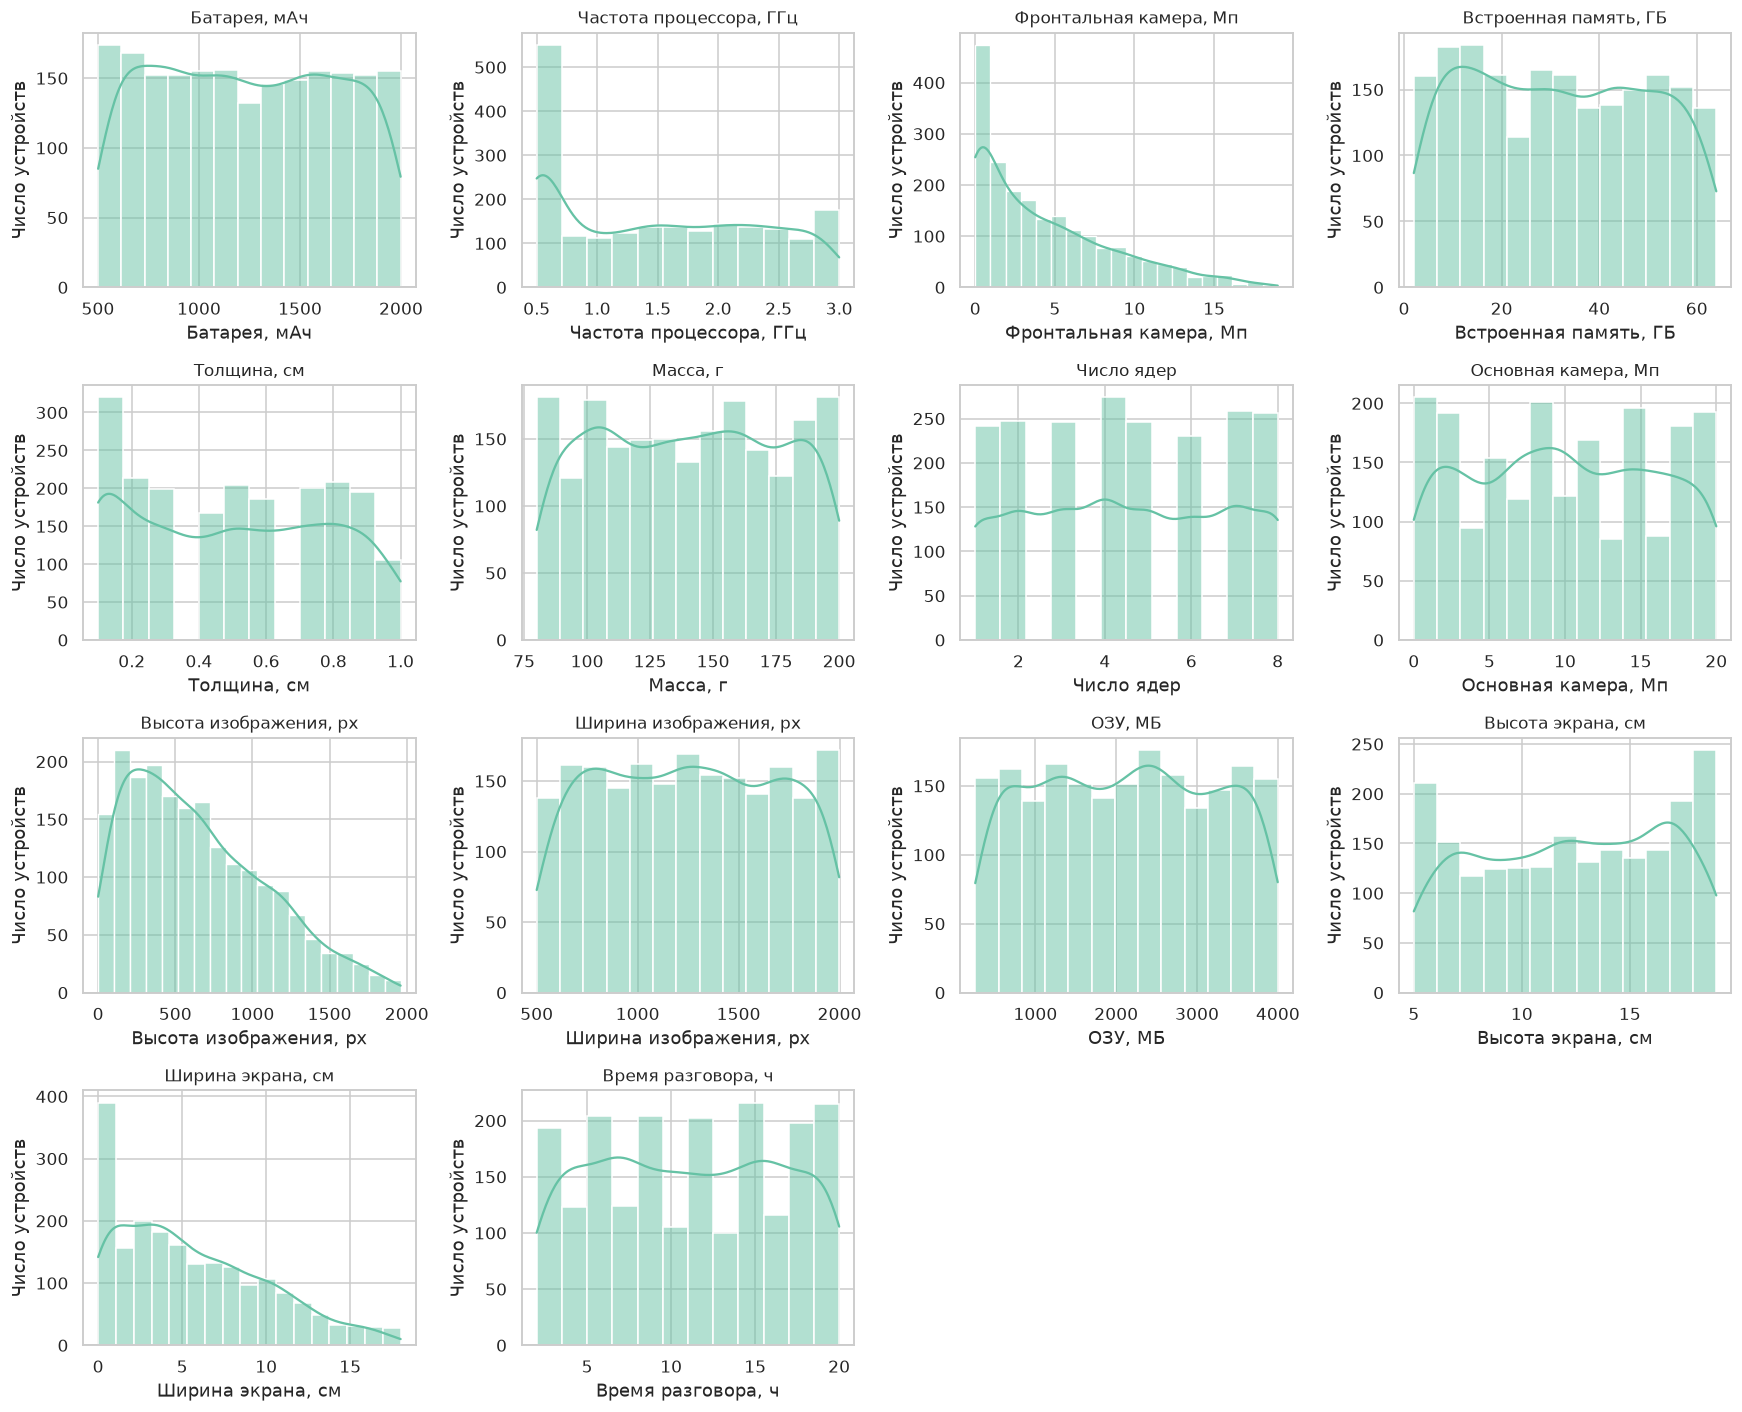

,W,p
признак,,
"Батарея, мАч",0.951884,4.012365e-25
"Частота процессора, ГГц",0.911232,1.137524e-32
"Фронтальная камера, Мп",0.873743,1.738698e-37
"Встроенная память, ГБ",0.952742,6.445696e-25
"Толщина, см",0.925406,2.024814e-30
"Масса, г",0.952758,6.505445e-25
Число ядер,0.926188,2.753812e-30
"Основная камера, Мп",0.951264,2.858949e-25
"Высота изображения, px",0.946905,2.886013e-26


In [4]:
binary = ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi']
continuous = [c for c in X_raw if c not in binary]
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
normality = []
for ax, col in zip(axes.flat, continuous):
    sns.histplot(X_raw[col], kde=True, ax=ax, color=sns.color_palette('Set2')[0])
    ax.set(title=FEATURE_LABELS[col], xlabel=FEATURE_LABELS[col], ylabel='Число устройств')
    W, p = shapiro(X_raw[col])
    normality.append({'признак': col, 'W': W, 'p': p})
for ax in axes.flat[len(continuous):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()
normality = pd.DataFrame(normality).set_index('признак')
display(normality.rename(index=FEATURE_LABELS))
rejected = int((normality.p < .05).sum())

analysis['distribution'] = (f'### Пояснение к распределениям и тесту Шапиро–Уилка\n\n'
    'На гистограммах столбики показывают число устройств, линия KDE сглаживает форму '
    'распределения. У ОЗУ и батареи нет узкой колоколообразной вершины: диапазон заполнен '
    'относительно равномерно. У фронтальной камеры и высоты экрана заметнее правый хвост. '
    f'Это согласуется с асимметрией: ram {stats.loc["ram", "skew"]:.3f}, '
    f'battery_power {stats.loc["battery_power", "skew"]:.3f}, fc {stats.loc["fc", "skew"]:.3f}, '
    f'px_height {stats.loc["px_height", "skew"]:.3f}.\n\n'
    f'Шапиро–Уилк рассчитан по всем {len(X_raw)} строкам каждого из {len(continuous)} '
    f'небинарных признаков. При уровне 0.05 нормальность отвергнута у {rejected} признаков. '
    f'Для ram p={normality.loc["ram", "p"]:.2e}, для батареи '
    f'p={normality.loc["battery_power", "p"]:.2e}. На такой выборке тест чувствителен '
    'и к небольшим отклонениям; множественные сравнения здесь не корректировались.\n\n'
    'Из этого не следует, что данные нельзя кластеризовать. K-Means не требует нормальных '
    'распределений отдельных столбцов. В GMM нормальные компоненты будут приближать '
    'локальную форму облака, но нормальный закон всего набора не установлен. Правый хвост '
    'также не позволяет без дополнительной проверки назвать распределение экспоненциальным.')

### Пояснение к распределениям и тесту Шапиро–Уилка

На гистограммах столбики показывают число устройств, линия KDE сглаживает форму распределения. У ОЗУ и батареи нет узкой колоколообразной вершины: диапазон заполнен относительно равномерно. У фронтальной камеры и высоты экрана заметнее правый хвост. Это согласуется с асимметрией: ram 0.007, battery_power 0.032, fc 1.020, px_height 0.666.

Шапиро–Уилк рассчитан по всем 2000 строкам каждого из 14 небинарных признаков. При уровне 0.05 нормальность отвергнута у 14 признаков. Для ram p=1.87e-24, для батареи p=4.01e-25. На такой выборке тест чувствителен и к небольшим отклонениям; множественные сравнения здесь не корректировались.

Из этого не следует, что данные нельзя кластеризовать. K-Means не требует нормальных распределений отдельных столбцов. В GMM нормальные компоненты будут приближать локальную форму облака, но нормальный закон всего набора не установлен. Правый хвост также не позволяет без дополнительной проверки назвать распределение экспоненциальным.

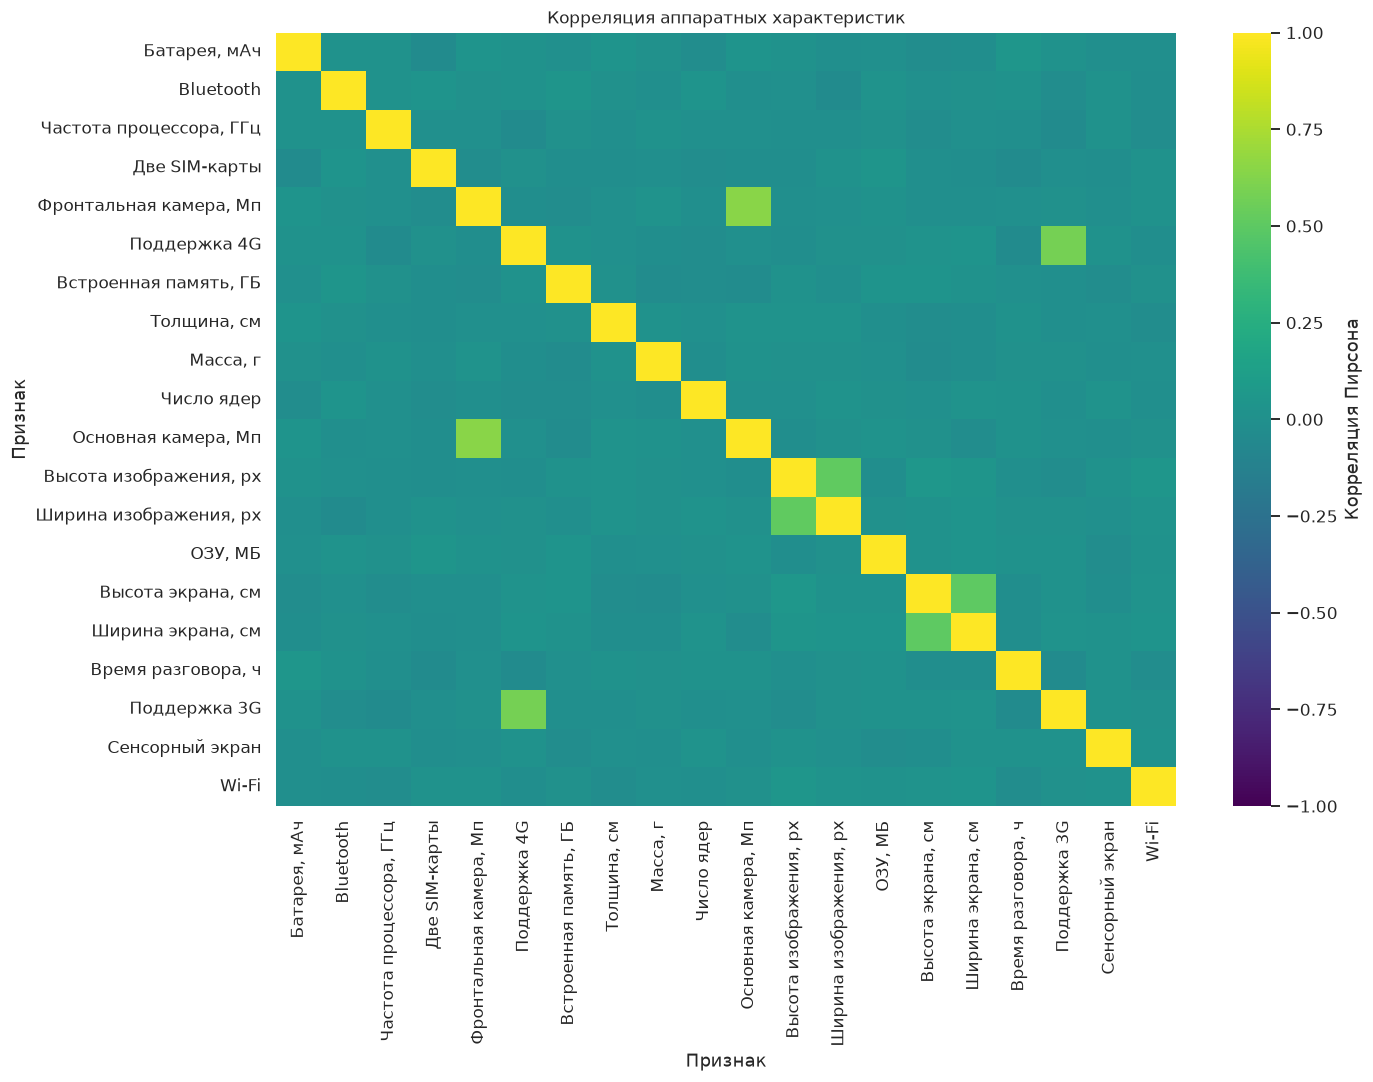

In [5]:
features = ['ram', 'battery_power', 'px_height', 'px_width', 'int_memory', 'mobile_wt', 'talk_time']
corr = X_raw.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr.rename(index=FEATURE_LABELS, columns=FEATURE_LABELS), cmap='viridis', vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Корреляция Пирсона'})
ax.set(title='Корреляция аппаратных характеристик', xlabel='Признак', ylabel='Признак')
plt.tight_layout(); plt.show()

correlation_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strongest_pairs = correlation_pairs.abs().nlargest(3)
analysis['correlations'] = ('### Пояснение к корреляциям и избыточности\n\n'
    'Диагональ тепловой карты всегда равна 1: каждый признак полностью совпадает с собой. '
    'Вне диагонали важны тесные связи между разными измерениями. Наиболее сильные пары: '
    + '; '.join(f'{a} и {b}: r={corr.loc[a, b]:.3f}' for a, b in strongest_pairs.index)
    + '. Это проверка повторяющейся информации, а не связь с ценовым классом.\n\n'
    f'Корреляция высоты и ширины изображения равна {corr.loc["px_height", "px_width"]:.3f}. '
    'Эти размеры описывают один экран, но не являются полной копией друг друга. Если '
    'сохранить несколько почти одинаковых столбцов, соответствующее свойство получит '
    'лишний вес в евклидовом расстоянии. Автоматическое удаление здесь не применяется: '
    'следующий блок проверяет выбранное подпространство без обращения к ценам.')

### Пояснение к корреляциям и избыточности

Диагональ тепловой карты всегда равна 1: каждый признак полностью совпадает с собой. Вне диагонали важны тесные связи между разными измерениями. Наиболее сильные пары: fc и pc: r=0.645; four_g и three_g: r=0.584; px_height и px_width: r=0.511. Это проверка повторяющейся информации, а не связь с ценовым классом.

Корреляция высоты и ширины изображения равна 0.511. Эти размеры описывают один экран, но не являются полной копией друг друга. Если сохранить несколько почти одинаковых столбцов, соответствующее свойство получит лишний вес в евклидовом расстоянии. Автоматическое удаление здесь не применяется: следующий блок проверяет выбранное подпространство без обращения к ценам.

In [6]:
X_selected = X_raw[features].copy()
selected_corr = X_selected.corr()
upper = np.abs(selected_corr.to_numpy()[np.triu_indices(len(features), 1)])
condition = np.linalg.cond(StandardScaler().fit_transform(X_selected))
display(stats.loc[features, ['variance', 'CV', 'skew']].rename(index=FEATURE_LABELS,
    columns={'variance': 'Дисперсия', 'skew': 'Асимметрия'}))

analysis['features'] = (f'### Пояснение к выбору признаков\n\n'
    f'Из {X_raw.shape[1]} характеристик для основного сравнения оставлено {len(features)}: '
    'ОЗУ, батарея, высота и ширина изображения, встроенная память, масса и время разговора. '
    'Они описывают ресурсы, экран и автономность устройства. Это предметный набор характеристик, '
    'а не отбор по тому, какой столбец лучше угадывает price_range.\n\n'
    f'Максимальный модуль корреляции внутри набора равен {upper.max():.3f}, число '
    f'обусловленности стандартизованной матрицы {condition:.3f}. Эти числа не указывают '
    'на почти точную линейную копию столбцов, но и не доказывают наличие отдельных групп. '
    f'Дисперсия ram={stats.loc["ram", "variance"]:.1f}, CV={stats.loc["ram", "CV"]:.3f}; '
    f'для talk_time дисперсия {stats.loc["talk_time", "variance"]:.2f}, '
    f'CV={stats.loc["talk_time", "CV"]:.3f}. Разница дисперсий подчёркивает необходимость масштаба.\n\n'
    'Шесть бинарных флагов исключены из основного евклидова пространства: стандартизация '
    'усилила бы дискретные переходы между вершинами гиперкуба. Частота процессора, толщина '
    'и число ядер также не включены в этот сценарий. Это ограничение выбранной модели, '
    'а не доказательство бесполезности этих характеристик для любой задачи.')

,Дисперсия,CV,Асимметрия
"ОЗУ, МБ",1.176644e+06,0.510651,0.006628
"Батарея, мАч",1.930884e+05,0.354793,0.031898
"Высота изображения, px",1.969414e+05,0.687917,0.666271
"Ширина изображения, px",1.867964e+05,0.345341,0.014787
"Встроенная память, ГБ",3.292670e+02,0.566231,0.057889
"Масса, г",1.253136e+03,0.252406,0.006558
"Время разговора, ч",2.985481e+01,0.496227,0.009512


### Пояснение к выбору признаков

Из 20 характеристик для основного сравнения оставлено 7: ОЗУ, батарея, высота и ширина изображения, встроенная память, масса и время разговора. Они описывают ресурсы, экран и автономность устройства. Это предметный набор характеристик, а не отбор по тому, какой столбец лучше угадывает price_range.

Максимальный модуль корреляции внутри набора равен 0.511, число обусловленности стандартизованной матрицы 1.761. Эти числа не указывают на почти точную линейную копию столбцов, но и не доказывают наличие отдельных групп. Дисперсия ram=1176643.6, CV=0.511; для talk_time дисперсия 29.85, CV=0.496. Разница дисперсий подчёркивает необходимость масштаба.

Шесть бинарных флагов исключены из основного евклидова пространства: стандартизация усилила бы дискретные переходы между вершинами гиперкуба. Частота процессора, толщина и число ядер также не включены в этот сценарий. Это ограничение выбранной модели, а не доказательство бесполезности этих характеристик для любой задачи.

,IQR,|Z|>3
"Батарея, мАч",0,0
"Частота процессора, ГГц",0,0
"Фронтальная камера, Мп",18,12
"Встроенная память, ГБ",0,0
"Толщина, см",0,0
"Масса, г",0,0
Число ядер,0,0
"Основная камера, Мп",0,0
"Высота изображения, px",2,0
"Ширина изображения, px",0,0


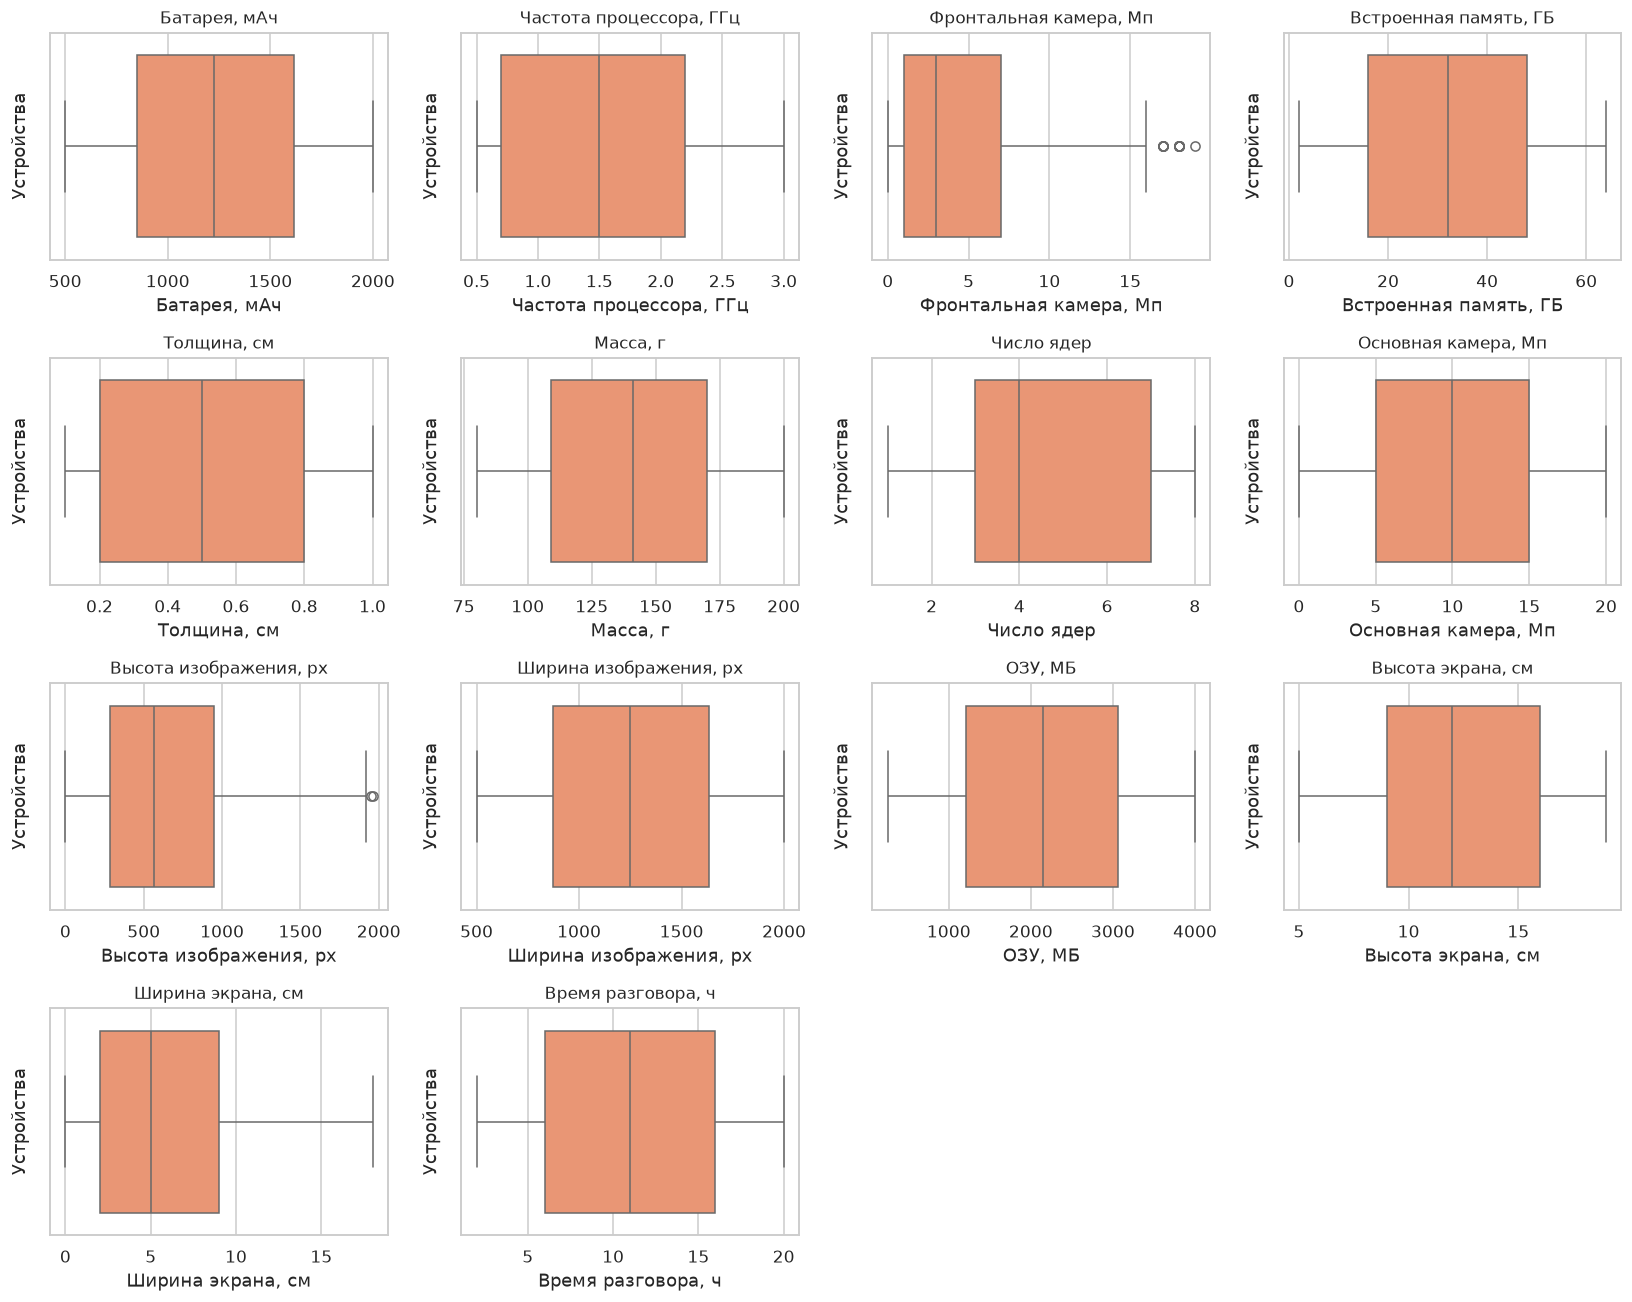

In [7]:
q1, q3 = X_raw[continuous].quantile(.25), X_raw[continuous].quantile(.75)
iqr = q3 - q1
iqr_flags = (X_raw[continuous] < q1 - 1.5 * iqr) | (X_raw[continuous] > q3 + 1.5 * iqr)
z_flags = pd.DataFrame(np.abs(zscore(X_raw[continuous])) > 3,
                       index=X_raw.index, columns=continuous)
outliers = pd.DataFrame({'IQR': iqr_flags.sum(), '|Z|>3': z_flags.sum()})
display(outliers.rename(index=FEATURE_LABELS))
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, col in zip(axes.flat, continuous):
    sns.boxplot(x=X_raw[col], ax=ax, color=sns.color_palette('Set2')[1])
    ax.set(title=FEATURE_LABELS[col], xlabel=FEATURE_LABELS[col], ylabel='Устройства')
for ax in axes.flat[len(continuous):]: ax.set_visible(False)
plt.tight_layout(); plt.show()

top_outliers = outliers.IQR.nlargest(3)
analysis['outlier_detection'] = ('### Пояснение к выбросам\n\n'
    'Прямоугольник boxplot содержит средние 50% значений. Усы доходят до 1.5 IQR '
    'от первого и третьего квартилей; точки дальше считаются статистически необычными. '
    'Больше всего IQR-флагов: ' + '; '.join(f'{col} — {int(n)}' for col, n in top_outliers.items())
    + f'. Хотя бы один IQR-флаг имеют {int(iqr_flags.any(axis=1).sum())} устройств '
    f'({iqr_flags.any(axis=1).mean():.1%} выборки).\n\n'
    f'Порог |Z|>3 отмечает {int(z_flags.any(axis=1).sum())} устройств. Два правила '
    'не обязаны совпадать: Z опирается на среднее и стандартное отклонение, а IQR '
    'на квартильную середину. После отвержения нормальности Z стоит читать как '
    'диагностику, а не как доказательство ошибки измерения.\n\n'
    'Необычный смартфон может быть корректным наблюдением. Поэтому строки не удаляются '
    'по объединению всех флагов. В следующем шаге ограничиваются только хвосты выбранных '
    'характеристик, для которых обнаружены аномалии; ценовые классы в этом решении не участвуют.')

### Пояснение к выбросам

Прямоугольник boxplot содержит средние 50% значений. Усы доходят до 1.5 IQR от первого и третьего квартилей; точки дальше считаются статистически необычными. Больше всего IQR-флагов: fc — 18; px_height — 2; battery_power — 0. Хотя бы один IQR-флаг имеют 20 устройств (1.0% выборки).

Порог |Z|>3 отмечает 12 устройств. Два правила не обязаны совпадать: Z опирается на среднее и стандартное отклонение, а IQR на квартильную середину. После отвержения нормальности Z стоит читать как диагностику, а не как доказательство ошибки измерения.

Необычный смартфон может быть корректным наблюдением. Поэтому строки не удаляются по объединению всех флагов. В следующем шаге ограничиваются только хвосты выбранных характеристик, для которых обнаружены аномалии; ценовые классы в этом решении не участвуют.

In [8]:
X_clean = X_selected.copy()
clipped = {}
for col in features:
    if (iqr_flags[col] | z_flags[col]).any():
        lo, hi = X_clean[col].quantile([.01, .99])
        old = X_clean[col].to_numpy().copy()
        X_clean[col] = np.clip(old, lo, hi)
        clipped[col] = int(np.count_nonzero(old != X_clean[col]))
assert X_clean.index.equals(y_true.index)

clip_details = []
for column, count in clipped.items():
    low, high = X_selected[column].quantile([.01, .99])
    clip_details.append(f'{column}: границы {low:.2f}–{high:.2f}, изменено {count} значений')
analysis['outliers'] = ('### Пояснение к обработке хвостов\n\n'
    + ('; '.join(clip_details) if clip_details else 'В выбранных признаках значения не изменялись')
    + f'. Всего после обработки осталось {len(X_clean)} строк, индексы совпадают с исходными. '
    'Винзоризация заменяет значения за 1-м и 99-м процентилями на ближайшую границу; '
    'в отличие от удаления, она сохраняет устройства и их соответствие эталону.\n\n'
    'Это компромисс: вместе с аномальными значениями ограничивается часть корректных '
    'крайних устройств. Поэтому метод и число замен указаны явно. Нули высоты экрана '
    'сохранены как значения источника; они физически сомнительны, но заменять их '
    'придуманными измерениями без дополнительной информации нельзя. Далее анализируется '
    'именно обработанная таблица, а не неизменённые исходные хвосты.')

### Пояснение к обработке хвостов

px_height: границы 15.00–1791.01, изменено 39 значений. Всего после обработки осталось 2000 строк, индексы совпадают с исходными. Винзоризация заменяет значения за 1-м и 99-м процентилями на ближайшую границу; в отличие от удаления, она сохраняет устройства и их соответствие эталону.

Это компромисс: вместе с аномальными значениями ограничивается часть корректных крайних устройств. Поэтому метод и число замен указаны явно. Нули высоты экрана сохранены как значения источника; они физически сомнительны, но заменять их придуманными измерениями без дополнительной информации нельзя. Далее анализируется именно обработанная таблица, а не неизменённые исходные хвосты.

In [9]:
X_h = StandardScaler().fit_transform(X_clean)
hopkins_values = np.array([hopkins(X_h, random_state=RANDOM_STATE+i) for i in range(30)])
h_linear = hopkins(X_h, power=1)
h_raw = hopkins(StandardScaler().fit_transform(X_selected))
rng = np.random.default_rng(RANDOM_STATE)
null_values = []
for i in range(99):
    null_X = rng.uniform(X_h.min(axis=0), X_h.max(axis=0), X_h.shape)
    null_values.append(hopkins(null_X, random_state=RANDOM_STATE+i))
h_observed = hopkins(X_h)
empirical_p = (1 + np.count_nonzero(np.array(null_values) >= h_observed)) / 100
display(pd.Series({'H (степень d)': h_observed, 'H (степень 1)': h_linear,
                   'H до винзоризации': h_raw, 'H среднее 30 повторов': hopkins_values.mean(),
                   'H std': hopkins_values.std(ddof=1), 'uniform H среднее': np.mean(null_values),
                   'Монте-Карло p': empirical_p}))

analysis['hopkins_numbers'] = (f'### Пояснение к статистике Хопкинса\n\n'
    'Статистика сравнивает расстояния от реальных устройств до соседей с расстояниями '
    'от равномерно сгенерированных точек до выборки. При выбранной конвенции H около '
    '0.5 соответствует равномерному заполнению области, а значение ближе к 1 — отклонению от него. '
    f'Для семи стандартизованных признаков H={h_observed:.4f}. За 30 повторов среднее '
    f'{hopkins_values.mean():.4f}, стандартное отклонение {hopkins_values.std(ddof=1):.4f}; '
    'это разброс повторов, не доверительный интервал.\n\n'
    f'Расстояния возведены в степень размерности d={X_h.shape[1]}, соответствующую объёму шара. '
    f'Вариант без этой степени даёт {h_linear:.4f}. Порог 0.70 нельзя механически переносить '
    f'между двумя определениями. До винзоризации H={h_raw:.4f}; обработка хвостов меняет '
    'геометрию, поэтому вариант вычисления зафиксирован до сравнения моделей.')

H (степень d)            0.906737
H (степень 1)            0.532872
H до винзоризации        0.949196
H среднее 30 повторов    0.899780
H std                    0.025359
uniform H среднее        0.500222
Монте-Карло p            0.010000
dtype: float64

### Пояснение к статистике Хопкинса

Статистика сравнивает расстояния от реальных устройств до соседей с расстояниями от равномерно сгенерированных точек до выборки. При выбранной конвенции H около 0.5 соответствует равномерному заполнению области, а значение ближе к 1 — отклонению от него. Для семи стандартизованных признаков H=0.9067. За 30 повторов среднее 0.8998, стандартное отклонение 0.0254; это разброс повторов, не доверительный интервал.

Расстояния возведены в степень размерности d=7, соответствующую объёму шара. Вариант без этой степени даёт 0.5329. Порог 0.70 нельзя механически переносить между двумя определениями. До винзоризации H=0.9492; обработка хвостов меняет геометрию, поэтому вариант вычисления зафиксирован до сравнения моделей.

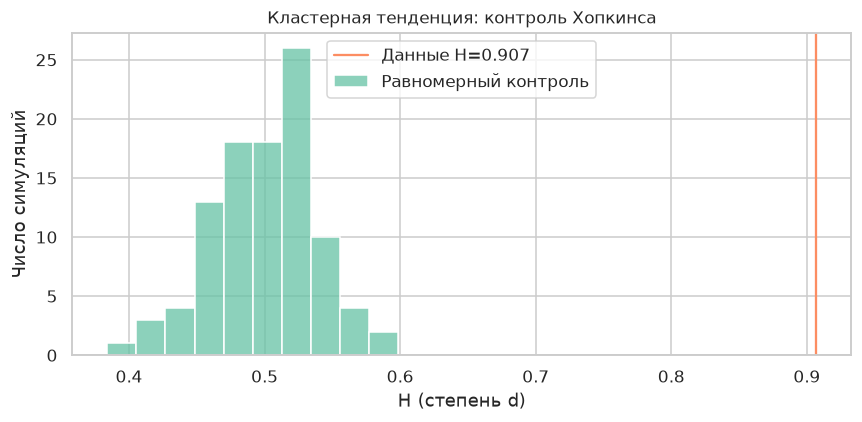

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(null_values, ax=ax, color=sns.color_palette('Set2')[0], label='Равномерный контроль')
ax.axvline(h_observed, color=sns.color_palette('Set2')[1], label=f'Данные H={h_observed:.3f}')
ax.set(title='Кластерная тенденция: контроль Хопкинса', xlabel='H (степень d)', ylabel='Число симуляций')
ax.legend(); plt.tight_layout(); plt.show()

analysis['hopkins'] = (f'### Пояснение к равномерному контролю\n\n'
    f'Гистограмма содержит {len(null_values)} симуляций равномерных облаков того же '
    f'размера и в тех же границах. Средний H контроля равен {np.mean(null_values):.4f}; '
    f'вертикальная линия данных находится на {h_observed:.4f}. Монте-Карло p={empirical_p:.2f}. '
    'С поправкой «плюс один» минимально возможное p в этом опыте равно 0.01.\n\n'
    f'Порог H>0.70 {"достигнут" if h_observed > .70 else "не достигнут"}. '
    'Но контроль отвергает равномерность внутри параллелепипеда, а не доказывает четыре '
    'изолированных ценовых сегмента. Корреляция размеров экрана и неравномерные распределения '
    'отдельных столбцов также повышают H. Поэтому исследование продолжается: качество '
    'отделения групп нужно проверить силуэтом и расстояниями между центрами.')

### Пояснение к равномерному контролю

Гистограмма содержит 99 симуляций равномерных облаков того же размера и в тех же границах. Средний H контроля равен 0.5002; вертикальная линия данных находится на 0.9067. Монте-Карло p=0.01. С поправкой «плюс один» минимально возможное p в этом опыте равно 0.01.

Порог H>0.70 достигнут. Но контроль отвергает равномерность внутри параллелепипеда, а не доказывает четыре изолированных ценовых сегмента. Корреляция размеров экрана и неравномерные распределения отдельных столбцов также повышают H. Поэтому исследование продолжается: качество отделения групп нужно проверить силуэтом и расстояниями между центрами.

## 3. Предобработка данных и визуальная оценка структуры

In [11]:
scalers = {'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler(), 'RobustScaler': RobustScaler()}
scaled = {name: sc.fit_transform(X_clean) for name, sc in scalers.items()}
scale_results = []
for name, values in scaled.items():
    labels = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit_predict(values)
    scale_results.append({'масштабирование': name, 'силуэт': silhouette_score(values, labels),
                          'CH': calinski_harabasz_score(values, labels), 'DB': davies_bouldin_score(values, labels)})
scale_results = pd.DataFrame(scale_results).set_index('масштабирование')
display(scale_results)
scaler = scalers['StandardScaler']
X = scaled['StandardScaler']
D = pairwise_distances(X)
np.fill_diagonal(D, 0)
assert np.max(np.abs(X.mean(axis=0))) < 1e-10
assert np.allclose(X.std(axis=0), 1)

analysis['scaling_numbers'] = ('### Пояснение к масштабированию\n\n'
    'StandardScaler вычитает среднее и делит признак на его стандартное отклонение. '
    f'После преобразования максимальное |среднее| по столбцам {np.abs(X.mean(axis=0)).max():.2e}, '
    f'а стандартные отклонения лежат в {X.std(axis=0).min():.3f}–{X.std(axis=0).max():.3f}. '
    'Речь о σ с ddof=0, используемом скалером. В квадрат расстояния вклад признака '
    'входит как (xᵢ−xⱼ)²/σ², поэтому мегабайты не подавляют часы только из-за единиц.\n\n'
    'В таблице для одного и того же k=4 получены силуэты: '
    + '; '.join(f'{name} — {row["силуэт"]:.4f}' for name, row in scale_results.iterrows())
    + '. MinMax привязывает шкалу к минимуму и максимуму, Robust — к медиане и IQR. '
    'У этих вариантов разные расстояния, поэтому сравнение не является абсолютным рейтингом. '
    'Основной StandardScaler выбран заранее для сопоставимых дисперсий; цены в скалер не входят.')

,силуэт,CH,DB
масштабирование,,,
StandardScaler,0.114419,256.329668,2.095854
MinMaxScaler,0.115360,244.506449,2.070852
RobustScaler,0.119637,280.970675,2.061759


### Пояснение к масштабированию

StandardScaler вычитает среднее и делит признак на его стандартное отклонение. После преобразования максимальное |среднее| по столбцам 2.15e-16, а стандартные отклонения лежат в 1.000–1.000. Речь о σ с ddof=0, используемом скалером. В квадрат расстояния вклад признака входит как (xᵢ−xⱼ)²/σ², поэтому мегабайты не подавляют часы только из-за единиц.

В таблице для одного и того же k=4 получены силуэты: StandardScaler — 0.1144; MinMaxScaler — 0.1154; RobustScaler — 0.1196. MinMax привязывает шкалу к минимуму и максимуму, Robust — к медиане и IQR. У этих вариантов разные расстояния, поэтому сравнение не является абсолютным рейтингом. Основной StandardScaler выбран заранее для сопоставимых дисперсий; цены в скалер не входят.

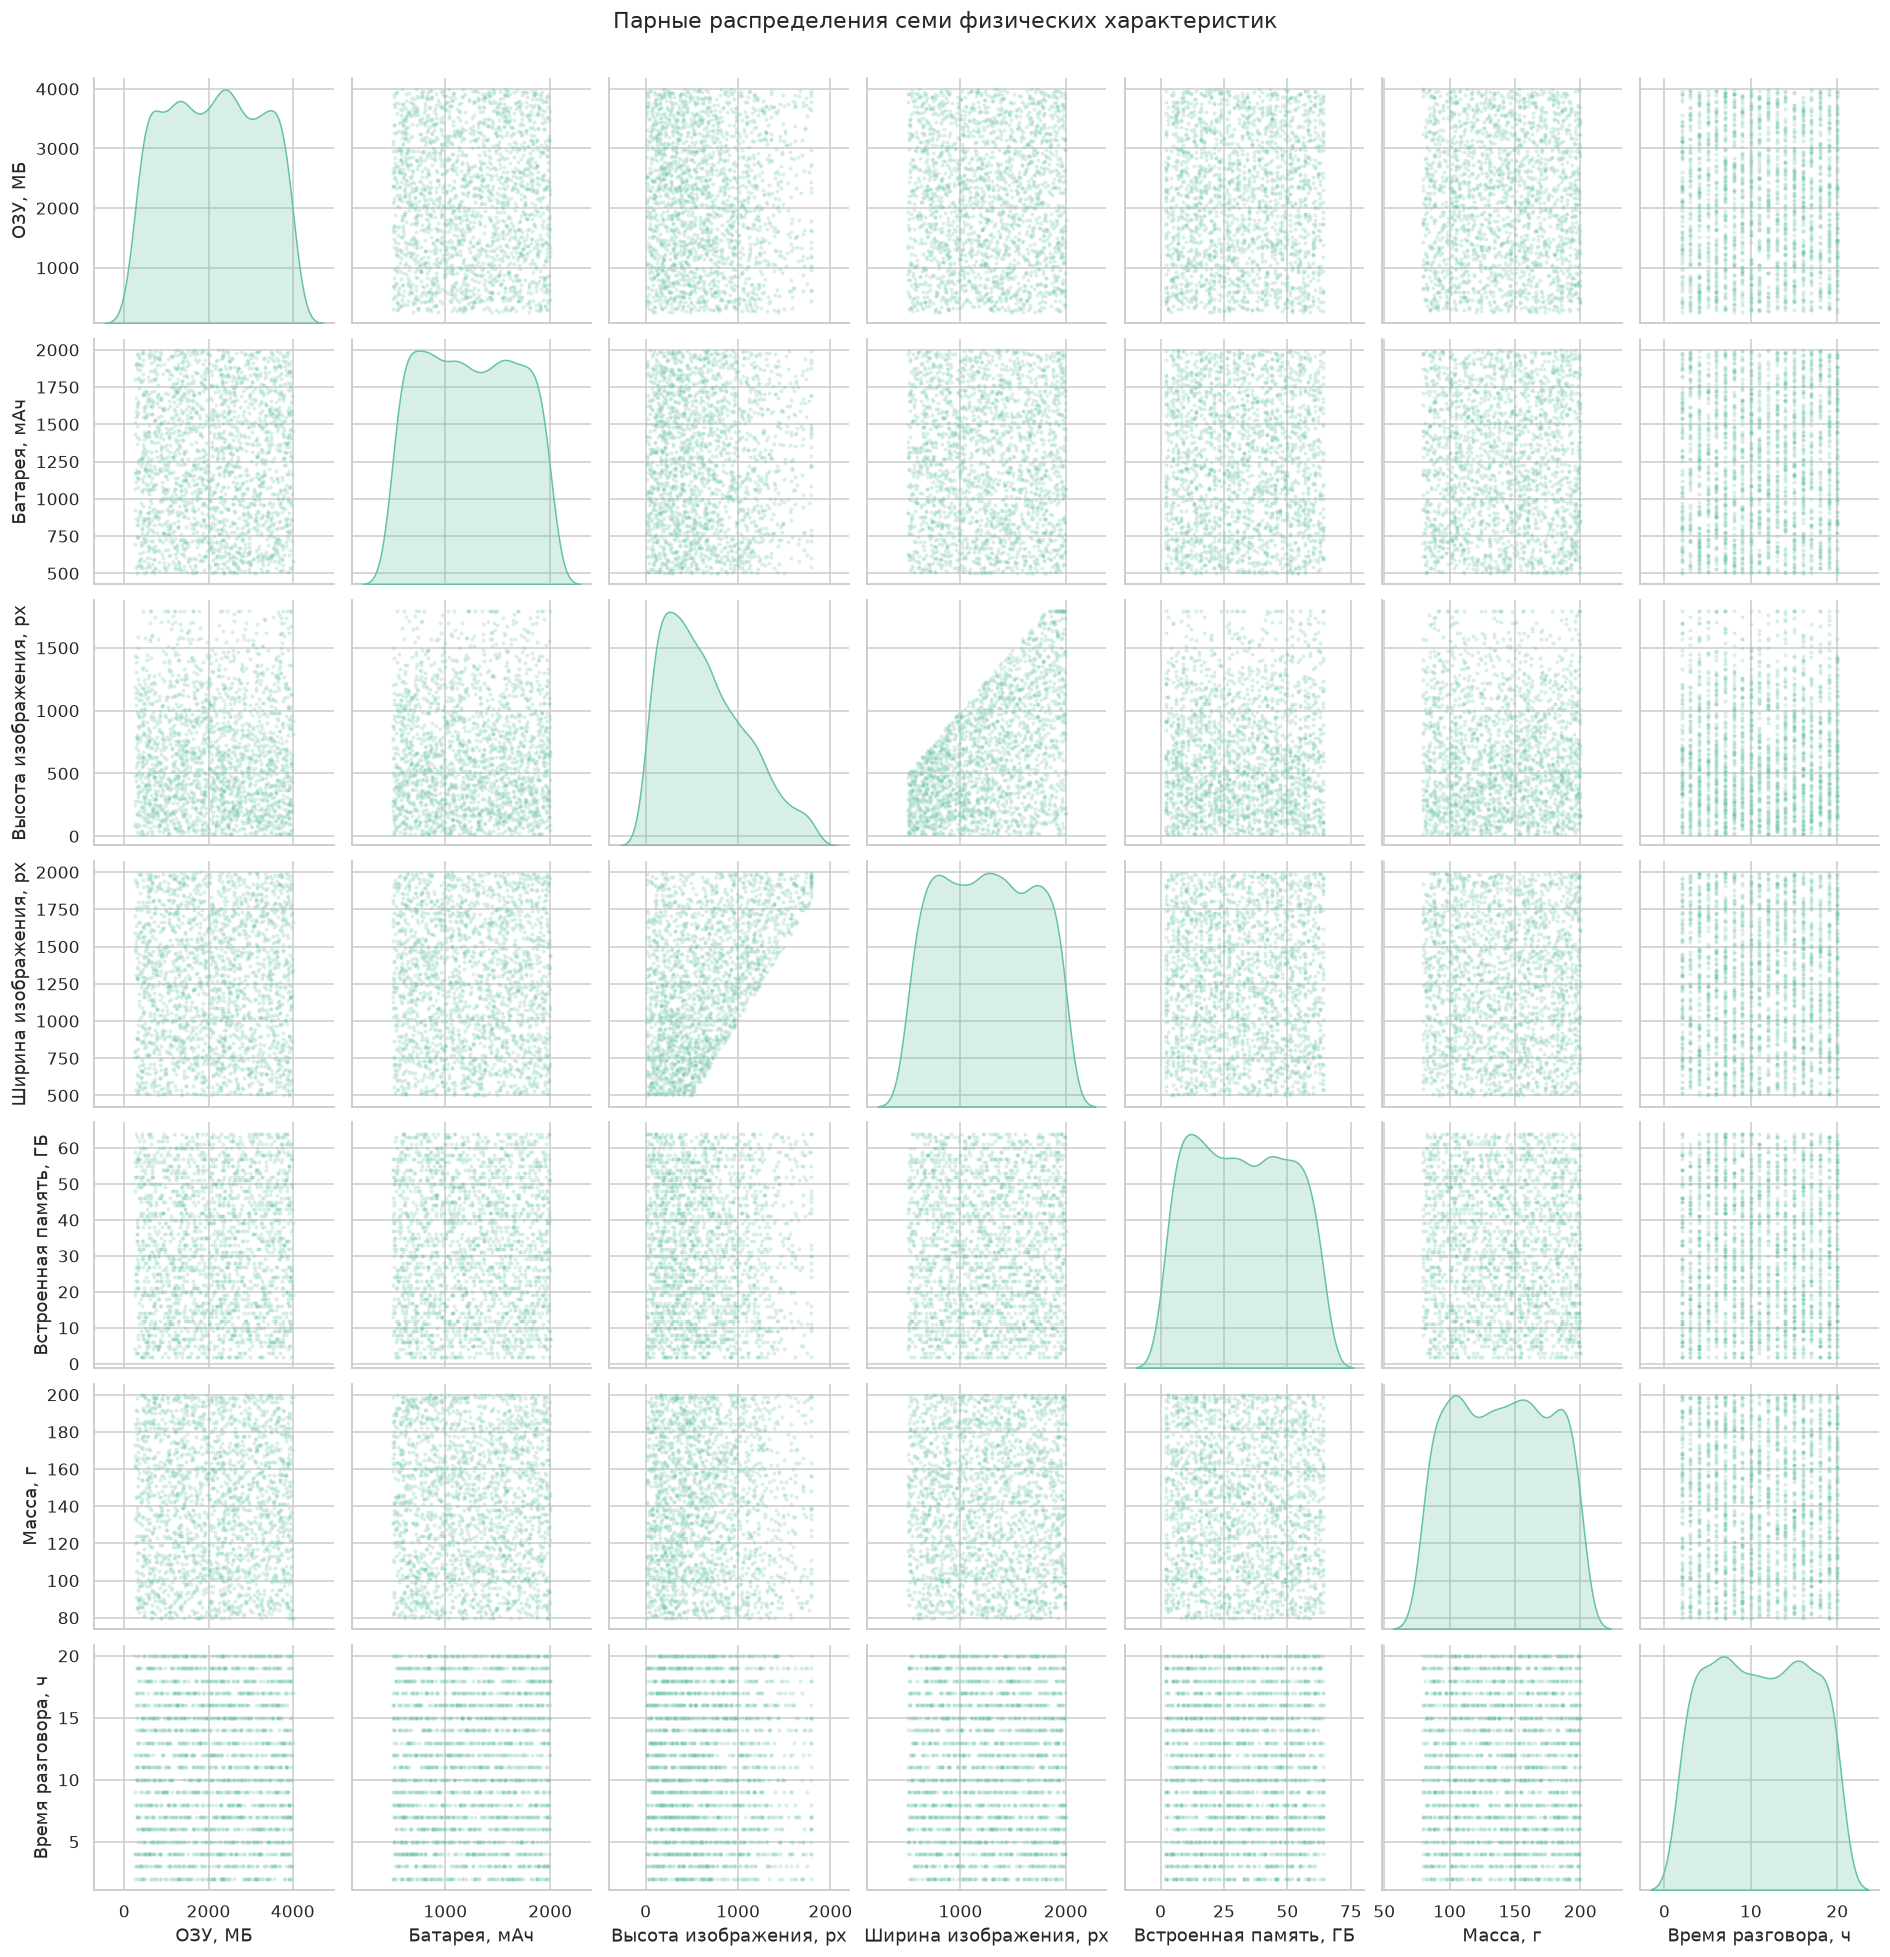

In [12]:
grid = sns.pairplot(X_clean.rename(columns=FEATURE_LABELS), diag_kind='kde', plot_kws={'s': 7, 'alpha': .25, 'color': sns.color_palette('Set2')[0]})
grid.figure.suptitle('Парные распределения семи физических характеристик', y=1.02)
plt.show()

analysis['scaling'] = (f'### Пояснение к матрице рассеивания\n\n'
    f'Матрица показывает {len(X_clean)} устройств в {len(features) ** 2} панелях. '
    'По диагонали — сглаженные плотности отдельных характеристик, вне диагонали — '
    'их пары в физических единицах. Кластеризации передаются стандартизованные значения, '
    'а исходные единицы на этом рисунке оставлены для чтения предметного смысла.\n\n'
    f'У пары высота–ширина экрана r={X_clean.px_height.corr(X_clean.px_width):.3f}: '
    'облако вытянуто и ограничено сочетаниями допустимых размеров. У многих других пар '
    'область заполнена без пустых промежутков, поэтому четыре отдельные группы заранее '
    'не видны. Одной матрицы недостаточно, чтобы уверенно выбрать k.\n\n'
    'K-Means будет строить области вокруг центров в евклидовой метрике. GMM допускает '
    'разные масштабы и наклон эллипсоидов. Это объясняет выбор пары методов; диапазон '
    '2–5 далее дополнительно рассмотрен через силуэтные профили, а поиск k расширен до 10.')

### Пояснение к матрице рассеивания

Матрица показывает 2000 устройств в 49 панелях. По диагонали — сглаженные плотности отдельных характеристик, вне диагонали — их пары в физических единицах. Кластеризации передаются стандартизованные значения, а исходные единицы на этом рисунке оставлены для чтения предметного смысла.

У пары высота–ширина экрана r=0.510: облако вытянуто и ограничено сочетаниями допустимых размеров. У многих других пар область заполнена без пустых промежутков, поэтому четыре отдельные группы заранее не видны. Одной матрицы недостаточно, чтобы уверенно выбрать k.

K-Means будет строить области вокруг центров в евклидовой метрике. GMM допускает разные масштабы и наклон эллипсоидов. Это объясняет выбор пары методов; диапазон 2–5 далее дополнительно рассмотрен через силуэтные профили, а поиск k расширен до 10.

## 4. Ход работы
### 4.1. Определение числа кластеров

In [13]:
def internal(labels):
    return {'силуэт': silhouette_score(D, labels, metric='precomputed'),
            'CH': calinski_harabasz_score(X, labels), 'DB': davies_bouldin_score(X, labels)}
k_models, rows = {}, []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    k_models[k] = model
    rows.append({'k': k, 'WCSS': model.inertia_, **internal(model.labels_)})
k_table = pd.DataFrame(rows).set_index('k')
display(k_table)

selection_lines = [f'- k={k}: WCSS={row.WCSS:.2f}, силуэт={row["силуэт"]:.4f}, CH={row.CH:.2f}, DB={row.DB:.4f}.'
                   for k, row in k_table.iterrows()]
analysis['selection_table'] = ('### Пояснение к таблице выбора числа групп\n\n'
    'Во всех строках используются одни и те же 2000 устройств и семь стандартизованных '
    'характеристик. Силуэт рассчитан полностью, без новой случайной подвыборки на каждом k. '
    'WCSS — сумма квадратов расстояний до своих центров; силуэт и CH лучше при больших '
    'значениях, DB — при меньших.\n\n' + '\n'.join(selection_lines)
    + '\n\nМинимальная WCSS обычно достигается при самом большом числе центров просто '
    'потому, что модель стала гибче. Поэтому её минимум не принимается за ответ: дальше '
    'сопоставляются форма кривой и отделённость групп.')

,WCSS,силуэт,CH,DB
k,,,,
2,11877.451056,0.145773,357.050748,2.306276
3,10822.915945,0.121731,293.111251,2.310750
4,10106.381970,0.114419,256.329668,2.095854
5,9544.885403,0.116408,232.793618,1.980717
6,9027.498543,0.115561,219.665899,2.017227
7,8585.586792,0.119613,209.477538,1.837146
8,8263.077756,0.118440,197.573375,1.835094
9,7957.732310,0.117408,188.969585,1.801123
10,7647.451544,0.125279,183.671520,1.711533


### Пояснение к таблице выбора числа групп

Во всех строках используются одни и те же 2000 устройств и семь стандартизованных характеристик. Силуэт рассчитан полностью, без новой случайной подвыборки на каждом k. WCSS — сумма квадратов расстояний до своих центров; силуэт и CH лучше при больших значениях, DB — при меньших.

- k=2: WCSS=11877.45, силуэт=0.1458, CH=357.05, DB=2.3063.
- k=3: WCSS=10822.92, силуэт=0.1217, CH=293.11, DB=2.3107.
- k=4: WCSS=10106.38, силуэт=0.1144, CH=256.33, DB=2.0959.
- k=5: WCSS=9544.89, силуэт=0.1164, CH=232.79, DB=1.9807.
- k=6: WCSS=9027.50, силуэт=0.1156, CH=219.67, DB=2.0172.
- k=7: WCSS=8585.59, силуэт=0.1196, CH=209.48, DB=1.8371.
- k=8: WCSS=8263.08, силуэт=0.1184, CH=197.57, DB=1.8351.
- k=9: WCSS=7957.73, силуэт=0.1174, CH=188.97, DB=1.8011.
- k=10: WCSS=7647.45, силуэт=0.1253, CH=183.67, DB=1.7115.

Минимальная WCSS обычно достигается при самом большом числе центров просто потому, что модель стала гибче. Поэтому её минимум не принимается за ответ: дальше сопоставляются форма кривой и отделённость групп.

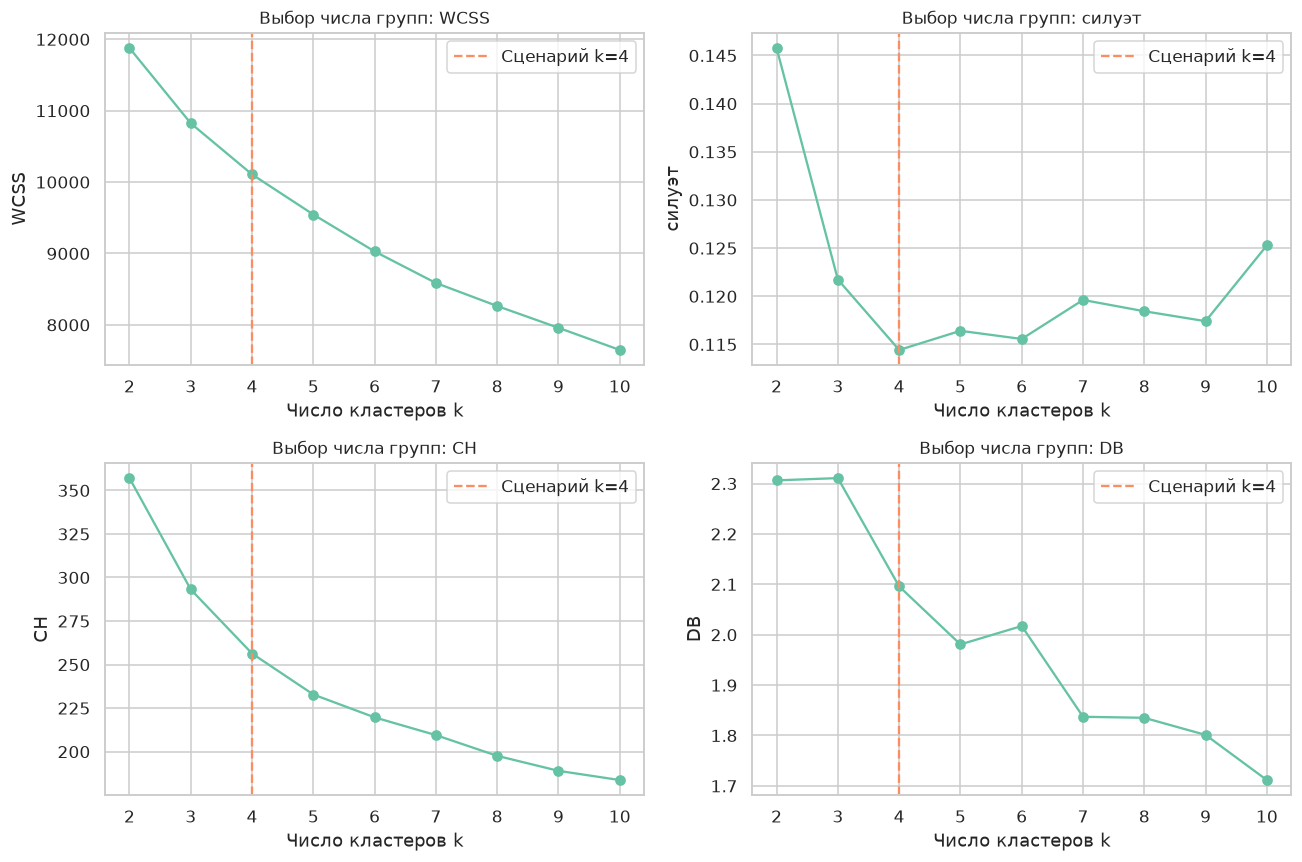

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ['WCSS', 'силуэт', 'CH', 'DB']):
    ax.plot(k_table.index, k_table[col], 'o-', color=sns.color_palette('Set2')[0])
    ax.axvline(4, ls='--', color=sns.color_palette('Set2')[1], label='Сценарий k=4')
    ax.set(title=f'Выбор числа групп: {col}', xlabel='Число кластеров k', ylabel=col)
    ax.legend()
plt.tight_layout(); plt.show()

analysis['selection_curves'] = (f'### Пояснение к кривым локтя и внутренних метрик\n\n'
    f'Максимальный силуэт равен {k_table["силуэт"].max():.4f} при k={int(k_table["силуэт"].idxmax())}. '
    f'При четырёх группах он равен {k_table.loc[4, "силуэт"]:.4f}. '
    f'CH максимален при k={int(k_table.CH.idxmax())}, DB минимален при k={int(k_table.DB.idxmin())}. '
    'Эти критерии оценивают разные стороны разбиения и не обязаны выбирать одинаковое число групп.\n\n'
    f'WCSS уменьшается с {k_table.WCSS.iloc[0]:.2f} при k=2 до {k_table.WCSS.iloc[-1]:.2f} '
    'при k=10. Ниже локоть будет оценён как максимальный отступ нормированной кривой '
    'от хорды. Это воспроизводимая эвристика замедления, а не проверка существования ценовых классов.\n\n'
    'Пунктир на четвёрке обозначает исследуемую модель технической сегментации. '
    'Она сопоставляется с числом групп, которое рекомендует максимум силуэта. '
    'Четыре группы позволяют рассмотреть более подробные технические портреты, '
    'но называть четвёрку оптимумом по силуэту нельзя.')

### Пояснение к кривым локтя и внутренних метрик

Максимальный силуэт равен 0.1458 при k=2. При четырёх группах он равен 0.1144. CH максимален при k=2, DB минимален при k=10. Эти критерии оценивают разные стороны разбиения и не обязаны выбирать одинаковое число групп.

WCSS уменьшается с 11877.45 при k=2 до 7647.45 при k=10. Ниже локоть будет оценён как максимальный отступ нормированной кривой от хорды. Это воспроизводимая эвристика замедления, а не проверка существования ценовых классов.

Пунктир на четвёрке обозначает исследуемую модель технической сегментации. Она сопоставляется с числом групп, которое рекомендует максимум силуэта. Четыре группы позволяют рассмотреть более подробные технические портреты, но называть четвёрку оптимумом по силуэту нельзя.

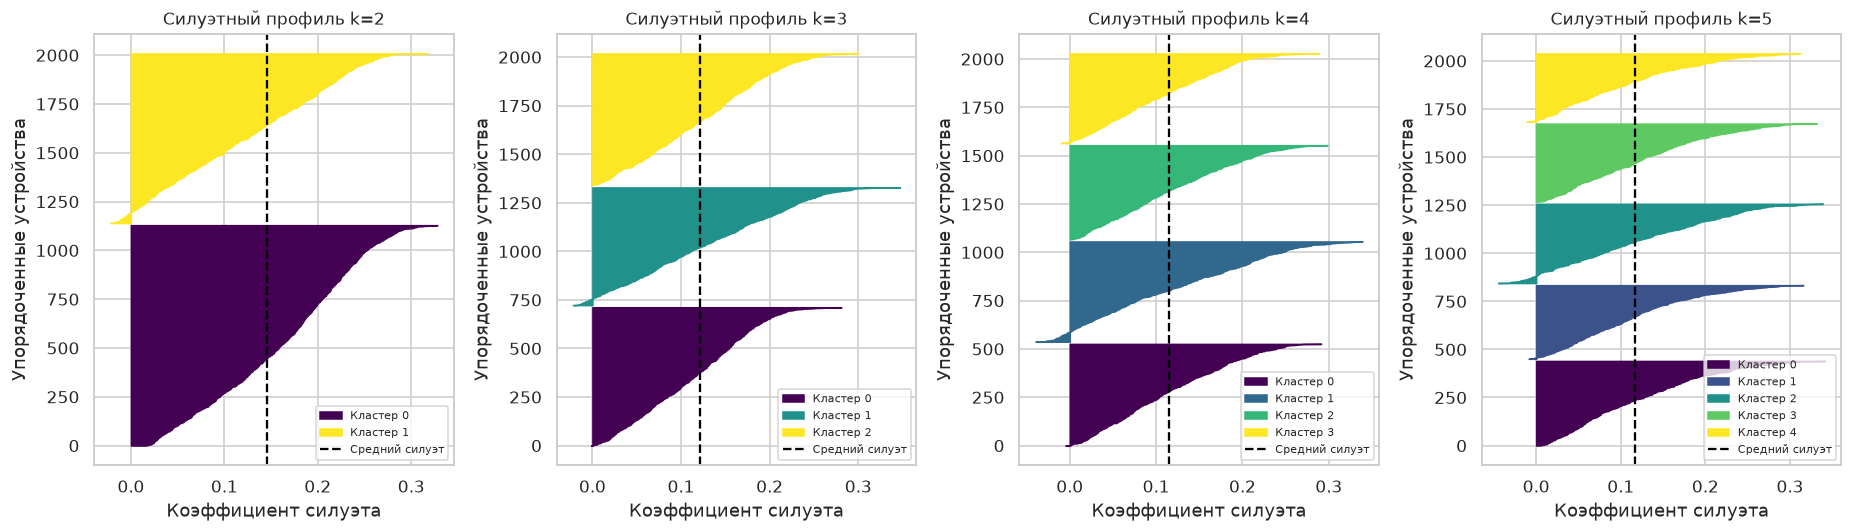

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(17, 5))
for ax, k in zip(axes, [2, 3, 4, 5]):
    labels = k_models[k].labels_
    samples = silhouette_samples(D, labels, metric='precomputed')
    start = 0
    for cluster in range(k):
        vals = np.sort(samples[labels == cluster])
        ax.fill_betweenx(np.arange(start, start + len(vals)), 0, vals,
                         color=plt.cm.viridis(cluster / max(1, k-1)), label=f'Кластер {cluster}')
        start += len(vals) + 10
    ax.axvline(samples.mean(), color='black', ls='--', label='Средний силуэт')
    ax.set(title=f'Силуэтный профиль k={k}', xlabel='Коэффициент силуэта', ylabel='Упорядоченные устройства')
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

profile_lines = []
for profile_k in [2, 3, 4, 5]:
    profile_s = silhouette_samples(D, k_models[profile_k].labels_, metric='precomputed')
    profile_lines.append(f'- k={profile_k}: средний силуэт {profile_s.mean():.4f}, '
                         f'отрицательных значений {int((profile_s < 0).sum())} ({(profile_s < 0).mean():.1%}).')
analysis['selection_profiles'] = ('### Пояснение к силуэтным профилям\n\n'
    'Каждая цветная полоса содержит устройства одного кластера, упорядоченные по силуэту. '
    'Ширина вправо означает, что устройство ближе к своим соседям, чем к чужим. '
    'Значение левее нуля означает, что по средним расстояниям соседняя группа выглядит ближе.\n\n'
    + '\n'.join(profile_lines)
    + '\n\nПри увеличении k единое облако дробится, но границы не обязательно становятся '
    'убедительнее. Поэтому среднее читается вместе с долей отрицательных значений и '
    'формой полос. Цвет показывает номер технической группы и не означает цену устройства.')

### Пояснение к силуэтным профилям

Каждая цветная полоса содержит устройства одного кластера, упорядоченные по силуэту. Ширина вправо означает, что устройство ближе к своим соседям, чем к чужим. Значение левее нуля означает, что по средним расстояниям соседняя группа выглядит ближе.

- k=2: средний силуэт 0.1458, отрицательных значений 56 (2.8%).
- k=3: средний силуэт 0.1217, отрицательных значений 36 (1.8%).
- k=4: средний силуэт 0.1144, отрицательных значений 64 (3.2%).
- k=5: средний силуэт 0.1164, отрицательных значений 54 (2.7%).

При увеличении k единое облако дробится, но границы не обязательно становятся убедительнее. Поэтому среднее читается вместе с долей отрицательных значений и формой полос. Цвет показывает номер технической группы и не означает цену устройства.

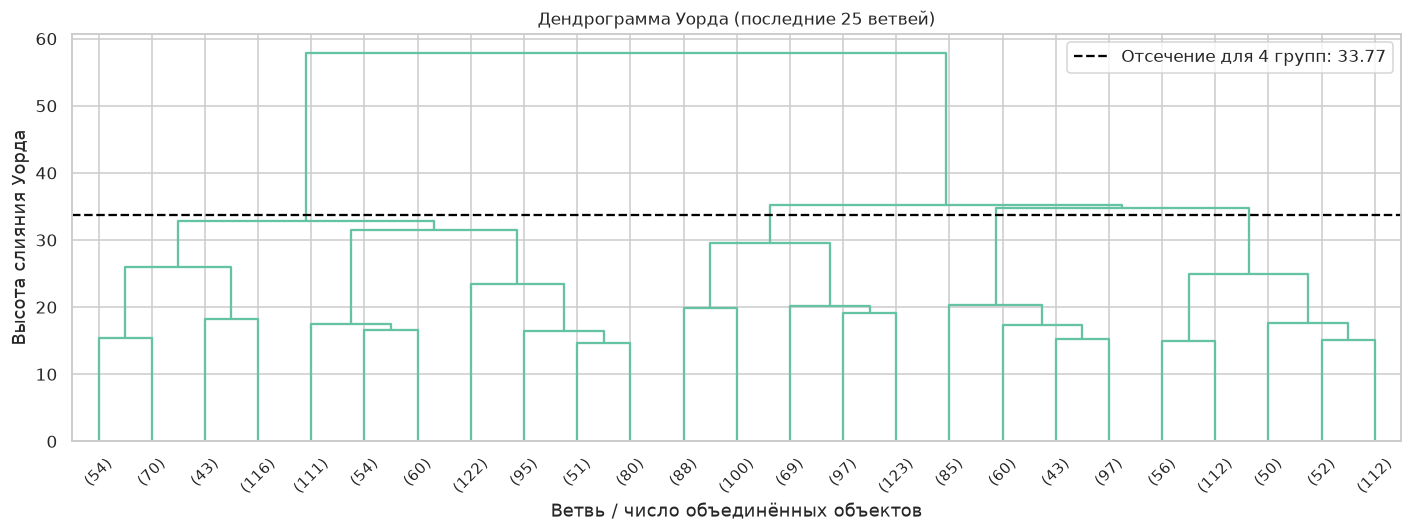

In [16]:
fig, ax = plt.subplots(figsize=(13, 5))
tree = linkage(X, method='ward')
dendrogram(tree, truncate_mode='lastp', p=25, ax=ax, above_threshold_color=sns.color_palette('Set2')[0],
           link_color_func=lambda _: '#66c2a5')
cut = (tree[-3, 2] + tree[-4, 2]) / 2
ax.axhline(cut, ls='--', color='black', label=f'Отсечение для 4 групп: {cut:.2f}')
ax.set(title='Дендрограмма Уорда (последние 25 ветвей)', xlabel='Ветвь / число объединённых объектов', ylabel='Высота слияния Уорда')
ax.legend(); plt.tight_layout(); plt.show()
best_k = int(k_table['силуэт'].idxmax())
# Воспроизводимая эвристика локтя: максимальный отступ от хорды нормированной WCSS.
kn = (k_table.index.to_numpy() - 2) / 8
wn = (k_table.WCSS.to_numpy() - k_table.WCSS.iloc[-1]) / (k_table.WCSS.iloc[0] - k_table.WCSS.iloc[-1])
elbow_k = int(k_table.index[np.argmax(1 - kn - wn)])

analysis['selection'] = (f'### Пояснение к дендрограмме и принятому k\n\n'
    'Дерево Уорда последовательно объединяет группы с наименьшим приростом внутригрупповой '
    'суммы квадратов. Высота узла показывает стоимость слияния, а не физическую цену '
    f'смартфона. Показаны последние 25 ветвей; отсечение на высоте {cut:.2f} даёт четыре группы.\n\n'
    f'Эвристика локтя дала k={elbow_k}, максимум силуэта — k={best_k}. '
    f'При k=4 WCSS={k_table.loc[4, "WCSS"]:.2f}, силуэт={k_table.loc[4, "силуэт"]:.4f}. '
    'Возможность провести линию для четырёх ветвей не делает это число доказанным оптимумом.\n\n'
    'Для дальнейшего сопоставления рассматриваются четыре технические группы. Тем самым '
    'проверяется подробная модель сегментации, а результат поиска '
    'по внутренним метрикам сообщается отдельно. Известные ценовые классы в эти расчёты не входили.')

### Пояснение к дендрограмме и принятому k

Дерево Уорда последовательно объединяет группы с наименьшим приростом внутригрупповой суммы квадратов. Высота узла показывает стоимость слияния, а не физическую цену смартфона. Показаны последние 25 ветвей; отсечение на высоте 33.77 даёт четыре группы.

Эвристика локтя дала k=5, максимум силуэта — k=2. При k=4 WCSS=10106.38, силуэт=0.1144. Возможность провести линию для четырёх ветвей не делает это число доказанным оптимумом.

Для дальнейшего сопоставления рассматриваются четыре технические группы. Тем самым проверяется подробная модель сегментации, а результат поиска по внутренним метрикам сообщается отдельно. Известные ценовые классы в эти расчёты не входили.

### 4.2. Обучение двух методов

In [17]:
km = k_models[4]
gmm = GaussianMixture(n_components=4, covariance_type='full', n_init=5,
                      max_iter=500, reg_covar=1e-6, random_state=RANDOM_STATE).fit(X)
assert gmm.converged_, 'EM не сошёлся'
models = {'K-Means': km, 'GMM': gmm}
labels_by_model = {'K-Means': km.labels_, 'GMM': gmm.predict(X)}
centers = {'K-Means': km.cluster_centers_, 'GMM': gmm.means_}
probabilities = gmm.predict_proba(X)
display(pd.DataFrame({name: np.bincount(labels, minlength=4) for name, labels in labels_by_model.items()})
        .rename_axis('Номер кластера'))

model_sizes = '; '.join(name + ': ' + ', '.join(f'{c} — {int((lab == c).sum())}' for c in range(4))
                        for name, lab in labels_by_model.items())
analysis['models'] = (f'### Пояснение к обучению K-Means и GMM\n\n'
    f'Оба метода получили те же {len(X)} строк и {X.shape[1]} признаков, но используют '
    'разные модели группы. K-Means назначает смартфон ближайшему центру, GMM вычисляет '
    'вероятности принадлежности компонентам и для таблицы выбирает наибольшую. '
    f'Размеры групп: {model_sizes}. Номера между двумя методами не выровнены и могут означать разные устройства.\n\n'
    f'K-Means остановился за {km.n_iter_} итераций при WCSS={km.inertia_:.2f}; '
    f'использовано {km.n_init} начальных запусков. GMM full сошёлся за {gmm.n_iter_} '
    f'итераций EM, BIC={gmm.bic(X):.2f}. У каждой компоненты своя полная ковариационная '
    'матрица, позволяющая наклон эллипсоида.\n\n'
    f'Средняя максимальная вероятность GMM равна {probabilities.max(axis=1).mean():.4f}. '
    'Это уверенность смеси в собственном назначении, а не доля правильно определённых '
    'цен. До этого шага price_range ни в один fit не передавался; его проверка начинается далее.')

,K-Means,GMM
Номер кластера,,
0,527,556
1,520,423
2,488,543
3,465,478


### Пояснение к обучению K-Means и GMM

Оба метода получили те же 2000 строк и 7 признаков, но используют разные модели группы. K-Means назначает смартфон ближайшему центру, GMM вычисляет вероятности принадлежности компонентам и для таблицы выбирает наибольшую. Размеры групп: K-Means: 0 — 527, 1 — 520, 2 — 488, 3 — 465; GMM: 0 — 556, 1 — 423, 2 — 543, 3 — 478. Номера между двумя методами не выровнены и могут означать разные устройства.

K-Means остановился за 79 итераций при WCSS=10106.38; использовано 20 начальных запусков. GMM full сошёлся за 24 итераций EM, BIC=39079.43. У каждой компоненты своя полная ковариационная матрица, позволяющая наклон эллипсоида.

Средняя максимальная вероятность GMM равна 0.8519. Это уверенность смеси в собственном назначении, а не доля правильно определённых цен. До этого шага price_range ни в один fit не передавался; его проверка начинается далее.

### 4.3. Внутренние, геометрические и внешние метрики

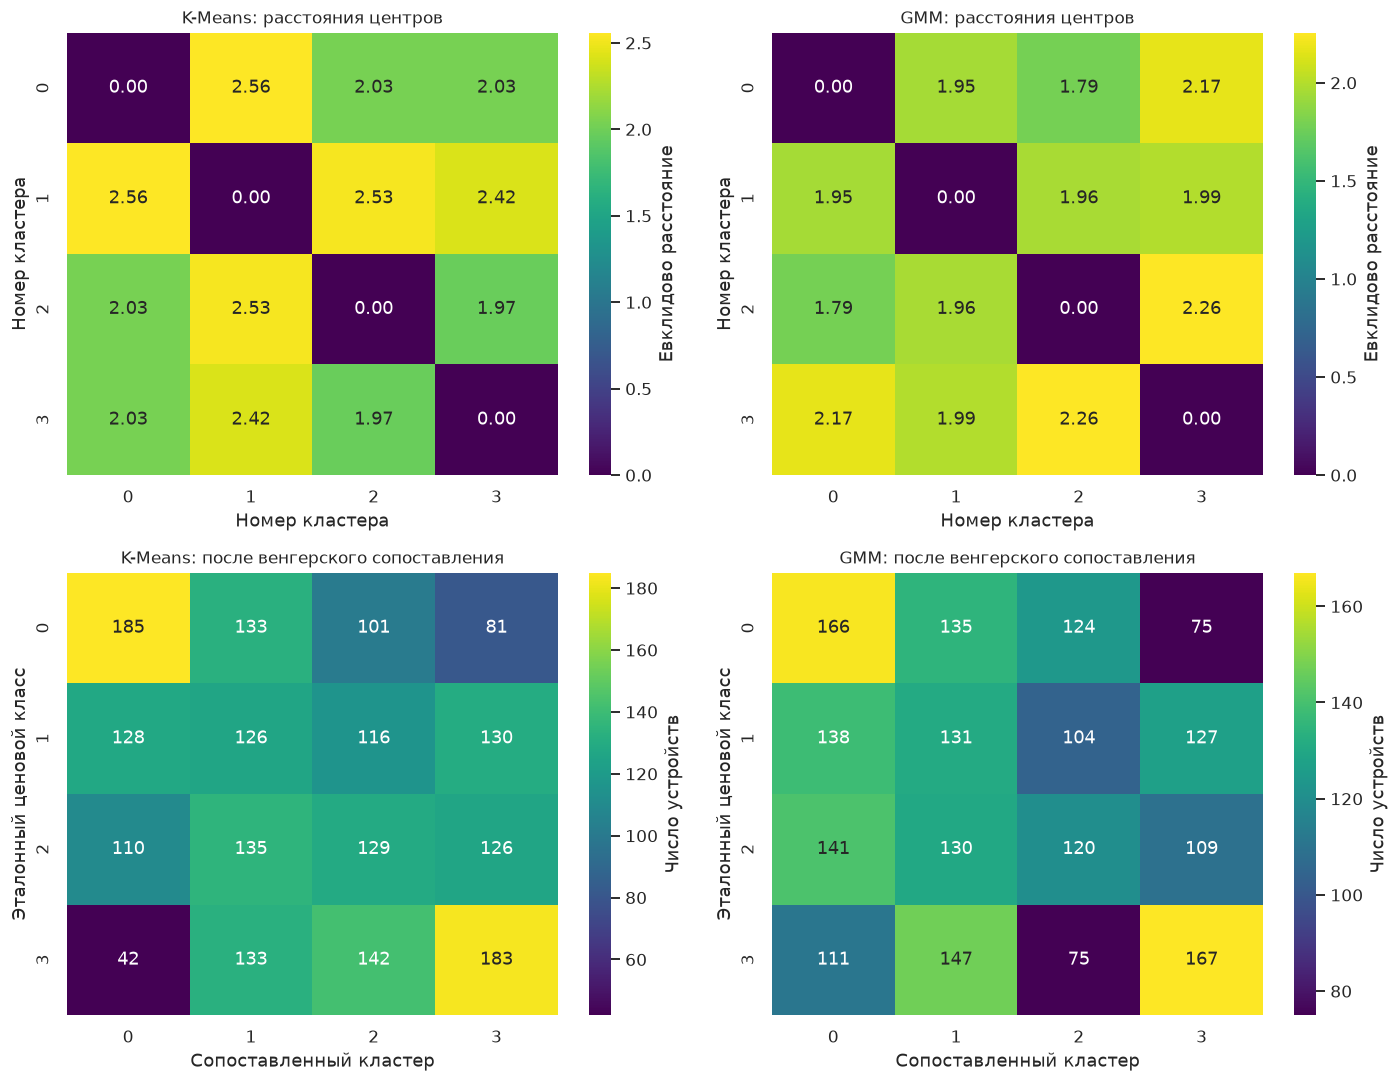

,силуэт,CH,DB,ARI,RI,Jaccard macro,NMI,Homogeneity,Completeness,V-measure,WCSS,BIC
метод,,,,,,,,,,,,
K-Means,0.114419,256.329668,2.095854,0.020668,0.632812,0.186459,0.026616,0.026604,0.026629,0.026616,10106.38197,NaN
GMM,0.091016,208.357160,2.306664,0.008603,0.627183,0.171379,0.011655,0.011630,0.011679,0.011655,NaN,39079.433975


размер  среднее расстояние до центра  радиус max  радиус 95%
метод   кластер                                                              
K-Means 0           527                      2.167253    3.502731    2.861707
        1           520                      2.303767    3.502254    3.016645
        2           488                      2.149710    3.371760    2.927972
        3           465                      2.182215    3.297320    2.848356
GMM     0           556                      2.221071    3.446588    2.967089
        1           423                      2.362794    3.946069    3.172460
        2           543                      2.213029    3.514995    2.954841
        3           478                      2.266599    3.701979    2.963689

In [18]:
metric_rows, geometry_rows, aligned_by_model, mappings = [], [], {}, {}
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for j, (name, labels) in enumerate(labels_by_model.items()):
    aligned, mapping = align_labels(y_true, labels)
    aligned_by_model[name], mappings[name] = aligned, mapping
    row = {'метод': name, **internal(labels), 'ARI': adjusted_rand_score(y_true, labels),
           'RI': rand_score(y_true, labels),
           'Jaccard macro': jaccard_score(y_true, aligned, average='macro', zero_division=0),
           'NMI': normalized_mutual_info_score(y_true, labels),
           'Homogeneity': homogeneity_score(y_true, labels),
           'Completeness': completeness_score(y_true, labels),
           'V-measure': v_measure_score(y_true, labels),
           'WCSS': km.inertia_ if name == 'K-Means' else np.nan,
           'BIC': gmm.bic(X) if name == 'GMM' else np.nan}
    metric_rows.append(row)
    distances = cdist(centers[name], centers[name])
    sns.heatmap(distances, annot=True, fmt='.2f', cmap='viridis', ax=axes[0, j],
                cbar_kws={'label': 'Евклидово расстояние'})
    axes[0, j].set(title=f'{name}: расстояния центров', xlabel='Номер кластера', ylabel='Номер кластера')
    cm = confusion_matrix(y_true, aligned, labels=[0, 1, 2, 3])
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', ax=axes[1, j],
                cbar_kws={'label': 'Число устройств'})
    axes[1, j].set(title=f'{name}: после венгерского сопоставления', xlabel='Сопоставленный кластер', ylabel='Эталонный ценовой класс')
    for c in range(4):
        d = np.linalg.norm(X[labels == c] - centers[name][c], axis=1)
        geometry_rows.append({'метод': name, 'кластер': c, 'размер': len(d),
                              'среднее расстояние до центра': d.mean(), 'радиус max': d.max(),
                              'радиус 95%': np.quantile(d, .95)})
plt.tight_layout(); plt.show()
metrics = pd.DataFrame(metric_rows).set_index('метод')
geometry = pd.DataFrame(geometry_rows).set_index(['метод', 'кластер'])
display(metrics); display(geometry)

metric_paragraphs = []
for method, row in metrics.iterrows():
    between = cdist(centers[method], centers[method])[np.triu_indices(4, 1)]
    geom = geometry.loc[method]
    metric_paragraphs.append(f'**{method}.** Силуэт {row["силуэт"]:.4f}, CH {row.CH:.2f}, '
        f'DB {row.DB:.4f}. Средние расстояния до центров по группам '
        f'{geom["среднее расстояние до центра"].min():.3f}–{geom["среднее расстояние до центра"].max():.3f}; '
        f'между центрами {between.min():.3f}–{between.max():.3f}. '
        f'RI {row.RI:.4f}, ARI {row.ARI:.4f}, NMI {row.NMI:.4f}, '
        f'Жаккар macro {row["Jaccard macro"]:.4f}, однородность {row.Homogeneity:.4f}, '
        f'полнота {row.Completeness:.4f}, V-measure {row["V-measure"]:.4f}.')
analysis['metrics'] = ('### Пояснение к метрикам и геометрии кластеров\n\n'
    'Верхние тепловые карты показывают расстояния между центрами в семи стандартизованных '
    'координатах. Нули на диагонали обязательны. В таблице геометрии среднее расстояние '
    'измеряет типичное удаление устройства от своего центра; радиус max описывает самый '
    'дальний объект, а радиус 95% меньше зависит от одиночных крайних точек.\n\n'
    + '\n\n'.join(metric_paragraphs)
    + '\n\nСредние расстояния до центров сопоставимы с межцентровыми расстояниями. '
    'Это согласуется с низкими силуэтами: модели разделяют перекрывающееся облако, '
    'а не четыре далеко разнесённых скопления. Высокий Hopkins этому не противоречит: '
    'он проверял отличие от равномерности, а не отделённость найденных групп.\n\n'
    'Нижние карты впервые используют цены. Венгерский алгоритм переставляет номера '
    'кластеров так, чтобы максимизировать число совпадений; это не обучение новых центров '
    'и не оптимизация самого macro Jaccard. RI учитывает также пары, разделённые в обоих '
    'разбиениях, поэтому может выглядеть высоким при ARI около нуля. ARI вычитает '
    'случайное согласие; малые ARI и NMI показывают слабое восстановление цен. '
    'WCSS и BIC имеют разные определения и не сравниваются как одна шкала. '
    'Оценка проведена на описываемой выборке и не является тестом на новых смартфонах.')

### Пояснение к метрикам и геометрии кластеров

Верхние тепловые карты показывают расстояния между центрами в семи стандартизованных координатах. Нули на диагонали обязательны. В таблице геометрии среднее расстояние измеряет типичное удаление устройства от своего центра; радиус max описывает самый дальний объект, а радиус 95% меньше зависит от одиночных крайних точек.

**K-Means.** Силуэт 0.1144, CH 256.33, DB 2.0959. Средние расстояния до центров по группам 2.150–2.304; между центрами 1.974–2.560. RI 0.6328, ARI 0.0207, NMI 0.0266, Жаккар macro 0.1865, однородность 0.0266, полнота 0.0266, V-measure 0.0266.

**GMM.** Силуэт 0.0910, CH 208.36, DB 2.3067. Средние расстояния до центров по группам 2.213–2.363; между центрами 1.785–2.256. RI 0.6272, ARI 0.0086, NMI 0.0117, Жаккар macro 0.1714, однородность 0.0116, полнота 0.0117, V-measure 0.0117.

Средние расстояния до центров сопоставимы с межцентровыми расстояниями. Это согласуется с низкими силуэтами: модели разделяют перекрывающееся облако, а не четыре далеко разнесённых скопления. Высокий Hopkins этому не противоречит: он проверял отличие от равномерности, а не отделённость найденных групп.

Нижние карты впервые используют цены. Венгерский алгоритм переставляет номера кластеров так, чтобы максимизировать число совпадений; это не обучение новых центров и не оптимизация самого macro Jaccard. RI учитывает также пары, разделённые в обоих разбиениях, поэтому может выглядеть высоким при ARI около нуля. ARI вычитает случайное согласие; малые ARI и NMI показывают слабое восстановление цен. WCSS и BIC имеют разные определения и не сравниваются как одна шкала. Оценка проведена на описываемой выборке и не является тестом на новых смартфонах.

### 4.4. Влияние гиперпараметров

,k,init,n_init,WCSS,силуэт,CH,DB,ARI
0,2,k-means++,1,11877.753485,0.146248,356.990785,2.302262,0.009335
1,2,k-means++,10,11877.746809,0.145917,357.002143,2.303788,0.007920
2,2,k-means++,20,11877.451056,0.145773,357.050748,2.306276,0.008769
3,2,random,1,11877.753485,0.146248,356.990785,2.302262,0.009335
4,2,random,10,11877.469425,0.145645,357.050349,2.307397,0.008534
...,...,...,...,...,...,...,...,...
61,12,k-means++,10,7221.584858,0.121843,169.636514,1.690469,0.071059
62,12,k-means++,20,7221.584858,0.121843,169.636514,1.690469,0.071059
63,12,random,1,7250.477781,0.122696,168.240326,1.672899,0.072331
64,12,random,10,7215.776681,0.125002,169.918532,1.641471,0.069894


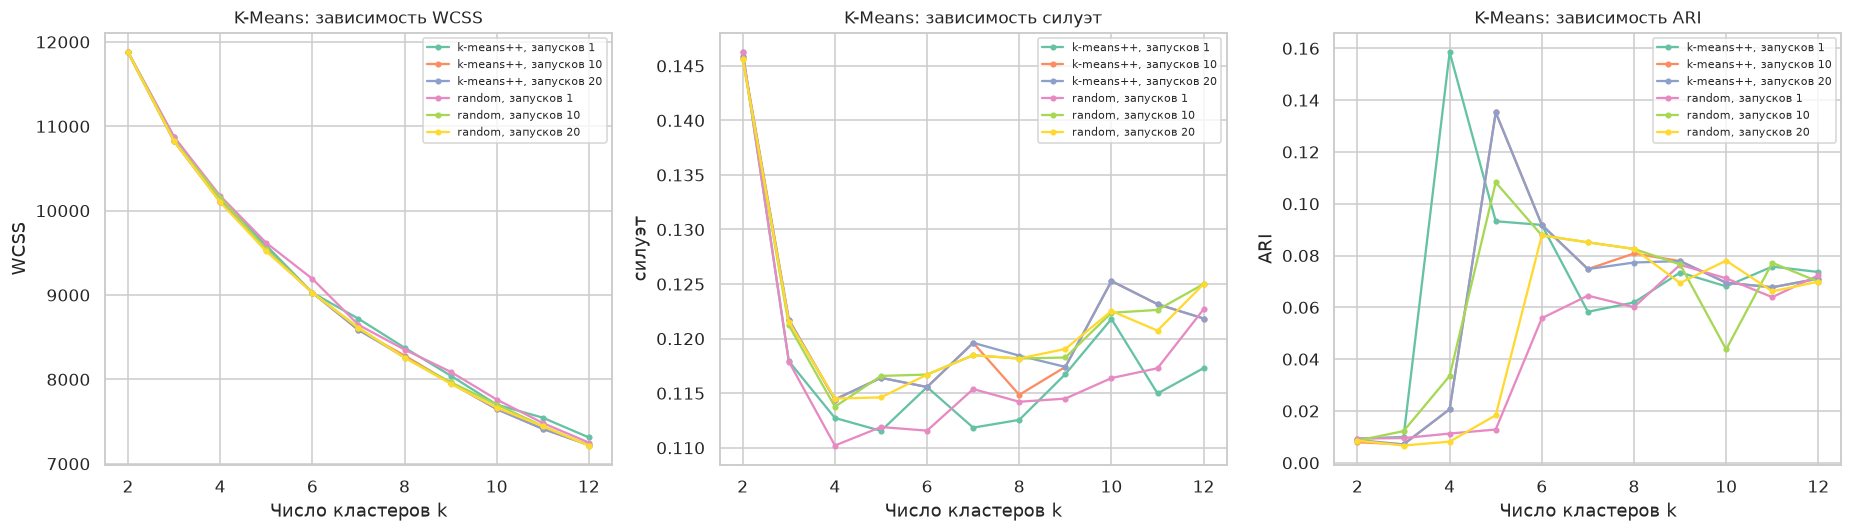

In [19]:
parameter_rows = []
for k in range(2, 13):
    for init in ['k-means++', 'random']:
        for n_init in [1, 10, 20]:
            model = KMeans(n_clusters=k, init=init, n_init=n_init, random_state=RANDOM_STATE).fit(X)
            parameter_rows.append({'k': k, 'init': init, 'n_init': n_init,
                                   'WCSS': model.inertia_, **internal(model.labels_),
                                   'ARI': adjusted_rand_score(y_true, model.labels_)})
parameters = pd.DataFrame(parameter_rows)
display(parameters)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ['WCSS', 'силуэт', 'ARI']):
    for (init, n), part in parameters.groupby(['init', 'n_init']):
        ax.plot(part.k, part[col], marker='.', label=f'{init}, запусков {n}')
    ax.set(title=f'K-Means: зависимость {col}', xlabel='Число кластеров k', ylabel=col)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

parameter_k4 = parameters[parameters.k == 4]
analysis['kmeans_parameters'] = (f'### Пояснение к параметрам K-Means\n\n'
    f'Проверено {len(parameters)} сочетаний: k от 2 до 12, две стратегии инициализации '
    'и 1, 10 или 20 перезапусков. Каждая линия на рисунках удерживает способ инициализации '
    'и число запусков неизменными; меняется только k.\n\n'
    f'При k=4 WCSS лежит в {parameter_k4.WCSS.min():.2f}–{parameter_k4.WCSS.max():.2f}, '
    f'силуэт в {parameter_k4["силуэт"].min():.4f}–{parameter_k4["силуэт"].max():.4f}, '
    f'ARI в {parameter_k4.ARI.min():.4f}–{parameter_k4.ARI.max():.4f}. '
    'Повторные старты дают больше шансов найти меньшую сумму квадратов, но не гарантируют '
    'лучшего совпадения с ценами: оптимизируется другая функция.\n\n'
    'График ARI — внешний разбор чувствительности после обучения. По его максимуму '
    'не меняются признаки, основное k и параметры модели. Один фиксированный seed '
    'позволяет воспроизвести сравнение, но не доказывает устойчивость ко всем случайным '
    'инициализациям или изменению состава данных.')

### Пояснение к параметрам K-Means

Проверено 66 сочетаний: k от 2 до 12, две стратегии инициализации и 1, 10 или 20 перезапусков. Каждая линия на рисунках удерживает способ инициализации и число запусков неизменными; меняется только k.

При k=4 WCSS лежит в 10100.71–10174.86, силуэт в 0.1102–0.1145, ARI в 0.0081–0.1585. Повторные старты дают больше шансов найти меньшую сумму квадратов, но не гарантируют лучшего совпадения с ценами: оптимизируется другая функция.

График ARI — внешний разбор чувствительности после обучения. По его максимуму не меняются признаки, основное k и параметры модели. Один фиксированный seed позволяет воспроизвести сравнение, но не доказывает устойчивость ко всем случайным инициализациям или изменению состава данных.

,силуэт,CH,DB,BIC,ARI
covariance_type,,,,,
full,0.091016,208.357160,2.306664,39079.433975,0.008603
tied,0.101138,225.998331,2.432551,38763.383553,0.005743
diag,0.101436,233.575979,2.468604,38642.403552,0.012203
spherical,0.114566,250.047009,2.244524,39536.091842,0.014236


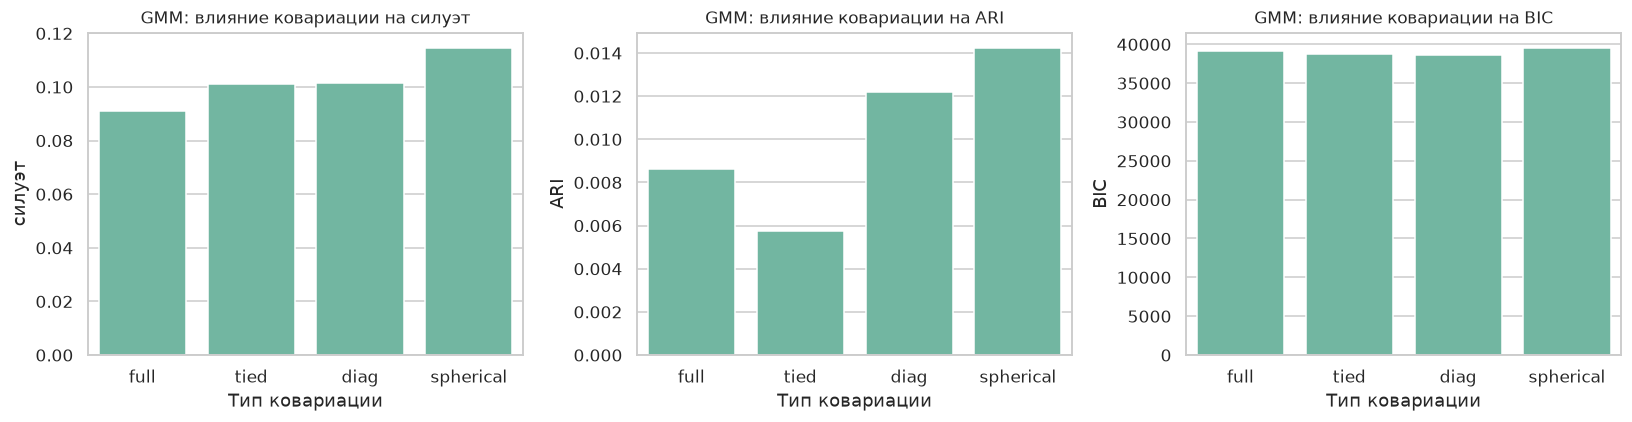

In [20]:
covariance_rows = []
for cov in ['full', 'tied', 'diag', 'spherical']:
    model = GaussianMixture(n_components=4, covariance_type=cov, n_init=5,
                            max_iter=500, random_state=RANDOM_STATE).fit(X)
    assert model.converged_, f'EM не сошёлся: {cov}'
    lab = model.predict(X)
    covariance_rows.append({'covariance_type': cov, **internal(lab), 'BIC': model.bic(X),
                            'ARI': adjusted_rand_score(y_true, lab)})
covariance_table = pd.DataFrame(covariance_rows).set_index('covariance_type')
display(covariance_table)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['силуэт', 'ARI', 'BIC']):
    sns.barplot(x=covariance_table.index, y=covariance_table[col], color=sns.color_palette('Set2')[0], ax=ax)
    ax.set(title=f'GMM: влияние ковариации на {col}', xlabel='Тип ковариации', ylabel=col)
plt.tight_layout(); plt.show()
sub = parameters[parameters.k == 4]

cov_lines = [f'- {cov}: силуэт {row["силуэт"]:.4f}, ARI {row.ARI:.4f}, BIC {row.BIC:.2f}.'
             for cov, row in covariance_table.iterrows()]
analysis['parameters'] = ('### Пояснение к типу ковариации GMM\n\n'
    'Full разрешает каждой компоненте свой повёрнутый эллипсоид. Tied задаёт общую '
    'ковариацию всем компонентам. Diag разрешает разный масштаб по осям без наклона, '
    'spherical оставляет одну дисперсию на компоненту. Число компонент во всех случаях равно четырём.\n\n'
    + '\n'.join(cov_lines)
    + f'\n\nНаибольший силуэт у {covariance_table["силуэт"].idxmax()}, '
    f'наименьший BIC у {covariance_table.BIC.idxmin()}. Силуэт сравнивает отделённость '
    'жёстких групп, BIC — правдоподобие смеси со штрафом за сложность, поэтому победители '
    'могут различаться. Full сохранён в основном сравнении для исследования модели '
    'с отдельными полными ковариациями компонент. Высота столбца ARI описывает связь '
    'с ценами постфактум и не используется для перенастройки.')

### Пояснение к типу ковариации GMM

Full разрешает каждой компоненте свой повёрнутый эллипсоид. Tied задаёт общую ковариацию всем компонентам. Diag разрешает разный масштаб по осям без наклона, spherical оставляет одну дисперсию на компоненту. Число компонент во всех случаях равно четырём.

- full: силуэт 0.0910, ARI 0.0086, BIC 39079.43.
- tied: силуэт 0.1011, ARI 0.0057, BIC 38763.38.
- diag: силуэт 0.1014, ARI 0.0122, BIC 38642.40.
- spherical: силуэт 0.1146, ARI 0.0142, BIC 39536.09.

Наибольший силуэт у spherical, наименьший BIC у diag. Силуэт сравнивает отделённость жёстких групп, BIC — правдоподобие смеси со штрафом за сложность, поэтому победители могут различаться. Full сохранён в основном сравнении для исследования модели с отдельными полными ковариациями компонент. Высота столбца ARI описывает связь с ценами постфактум и не используется для перенастройки.

,eps,min_samples,число кластеров,доля шума
0,0.5,3,0,1.0000
1,0.5,5,0,1.0000
2,0.5,10,0,1.0000
3,0.5,20,0,1.0000
4,1.0,3,129,0.5065
5,1.0,5,36,0.8260
6,1.0,10,0,1.0000
7,1.0,20,0,1.0000
8,1.5,3,1,0.0040
9,1.5,5,1,0.0065


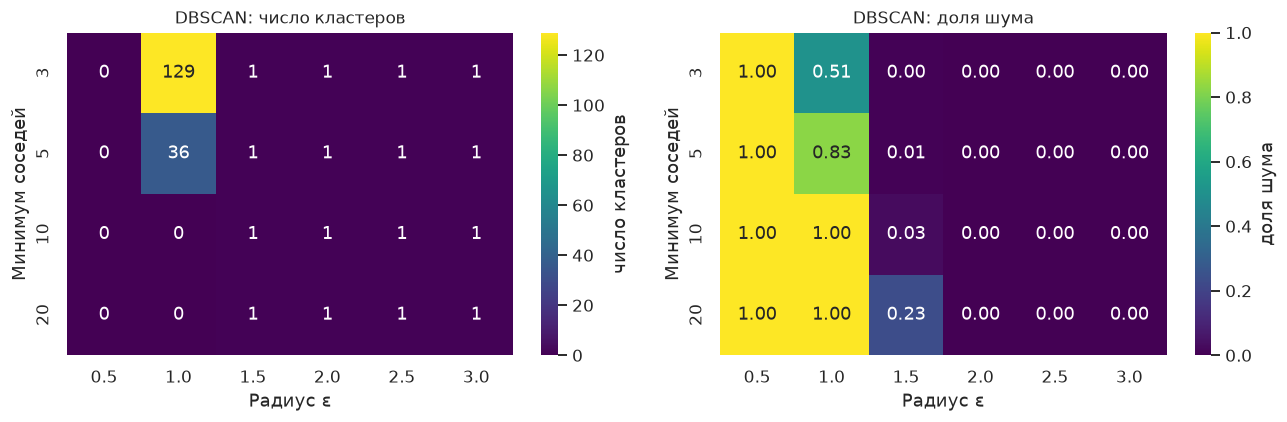

In [21]:
db_rows = []
for eps in np.arange(.5, 3.01, .5):
    for min_samples in [3, 5, 10, 20]:
        lab = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X)
        n_clusters = len(set(lab) - {-1})
        db_rows.append({'eps': eps, 'min_samples': min_samples, 'число кластеров': n_clusters,
                        'доля шума': np.mean(lab == -1)})
db_table = pd.DataFrame(db_rows)
display(db_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, fmt in zip(axes, ['число кластеров', 'доля шума'], ['.0f', '.2f']):
    sns.heatmap(db_table.pivot(index='min_samples', columns='eps', values=col), annot=True,
                fmt=fmt, cmap='viridis', ax=ax, cbar_kws={'label': col})
    ax.set(title=f'DBSCAN: {col}', xlabel='Радиус ε', ylabel='Минимум соседей')
plt.tight_layout(); plt.show()

analysis['dbscan'] = (f'### Пояснение к чувствительности DBSCAN\n\n'
    f'Две карты показывают {len(db_table)} конфигурации: ε от 0.5 до 3.0 и минимум '
    'соседей 3, 5, 10 или 20. Слева посчитаны группы без метки −1, справа доля устройств '
    f'с меткой шума. Число групп меняется от {db_table["число кластеров"].min()} '
    f'до {db_table["число кластеров"].max()}, доля шума от {db_table["доля шума"].min():.1%} '
    f'до {db_table["доля шума"].max():.1%}.\n\n'
    'При малом радиусе соседей недостаточно, облако распадается и много точек становится '
    'шумом. Большой радиус соединяет области цепочками соседей. Переход между этими '
    'режимами показывает, почему DBSCAN не выбран основным методом для данного '
    'пространства. Нулевое число групп означает, что все устройства признаны шумом; '
    'это не ошибка подсчёта и не отдельный ценовой сегмент.')

### Пояснение к чувствительности DBSCAN

Две карты показывают 24 конфигурации: ε от 0.5 до 3.0 и минимум соседей 3, 5, 10 или 20. Слева посчитаны группы без метки −1, справа доля устройств с меткой шума. Число групп меняется от 0 до 129, доля шума от 0.0% до 100.0%.

При малом радиусе соседей недостаточно, облако распадается и много точек становится шумом. Большой радиус соединяет области цепочками соседей. Переход между этими режимами показывает, почему DBSCAN не выбран основным методом для данного пространства. Нулевое число групп означает, что все устройства признаны шумом; это не ошибка подсчёта и не отдельный ценовой сегмент.

## 5. Визуализация результатов и профилирование кластеров

,Нагрузка PC1,Нагрузка PC2
ram,-0.022406,-0.065116
battery_power,0.008534,0.645713
px_height,0.707314,-0.002438
px_width,0.706468,-0.002751
int_memory,0.001154,-0.289499
mobile_wt,0.001961,0.276561
talk_time,-0.005424,0.646920


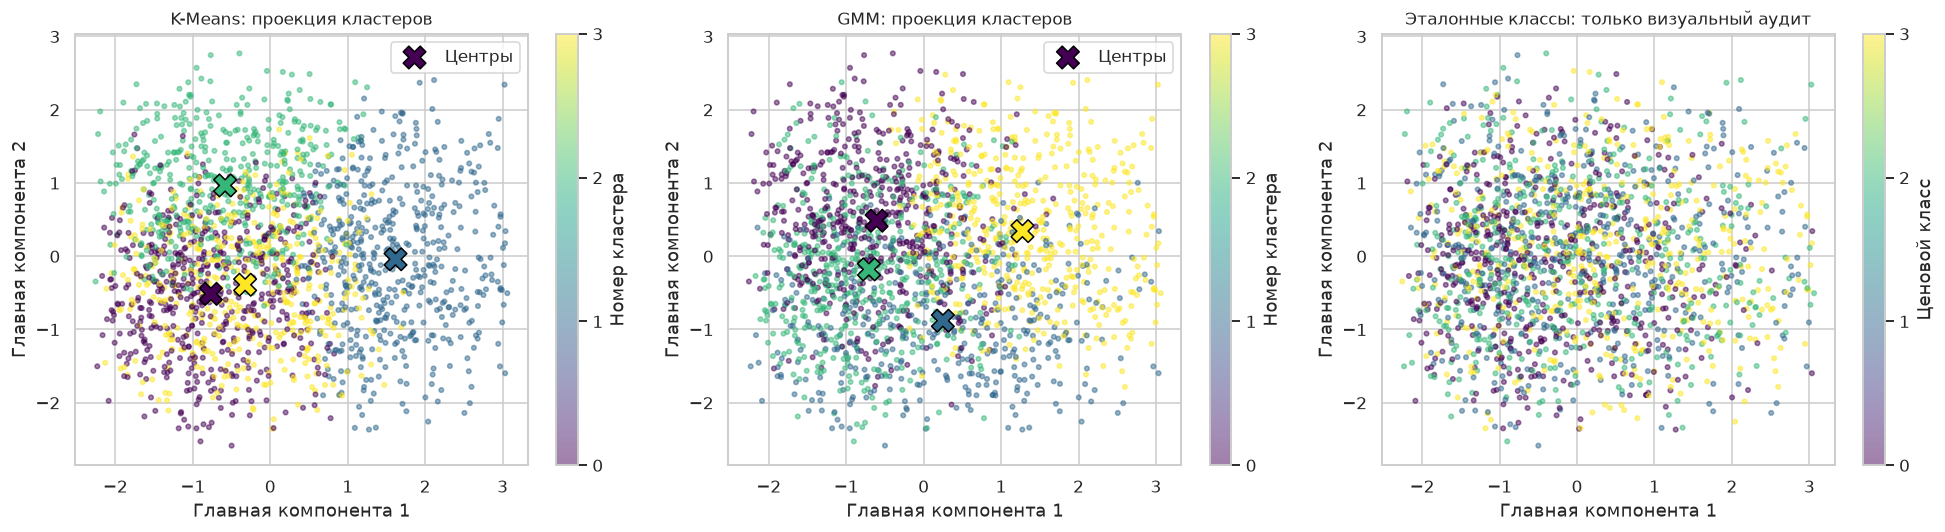

In [22]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
projection = pca.fit_transform(X)
display(pd.DataFrame(pca.components_.T, index=features, columns=['Нагрузка PC1', 'Нагрузка PC2']))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes[:2], ['K-Means', 'GMM']):
    sc = ax.scatter(*projection.T, c=labels_by_model[name], cmap='viridis', vmin=0, vmax=3, s=9, alpha=.5)
    cp = pca.transform(centers[name])
    ax.scatter(*cp.T, marker='X', s=220, c=np.arange(4), cmap='viridis', edgecolor='black', label='Центры')
    ax.set(title=f'{name}: проекция кластеров', xlabel='Главная компонента 1', ylabel='Главная компонента 2')
    ax.legend(); fig.colorbar(sc, ax=ax, ticks=range(4), label='Номер кластера')
sc = axes[2].scatter(*projection.T, c=y_true, cmap='viridis', vmin=0, vmax=3, s=9, alpha=.5)
axes[2].set(title='Эталонные классы: только визуальный аудит', xlabel='Главная компонента 1', ylabel='Главная компонента 2')
fig.colorbar(sc, ax=axes[2], ticks=range(4), label='Ценовой класс')
plt.tight_layout(); plt.show()

dominant_pc1 = features[int(np.abs(pca.components_[0]).argmax())]
dominant_pc2 = features[int(np.abs(pca.components_[1]).argmax())]
analysis['pca'] = (f'### Пояснение к PCA-визуализации\n\n'
    'Три панели используют одни и те же координаты. Левая раскрашена K-Means, средняя '
    'GMM, правая — эталонными ценами. Крупные X обозначают проекции обученных центров. '
    'Цвета между панелями не обязаны означать одну и ту же группу: номера произвольны.\n\n'
    f'Первая компонента сохраняет {pca.explained_variance_ratio_[0]:.2%} дисперсии, '
    f'вторая {pca.explained_variance_ratio_[1]:.2%}, вместе '
    f'{pca.explained_variance_ratio_.sum():.2%}. Наибольшая по модулю нагрузка PC1 '
    f'у {dominant_pc1}, PC2 у {dominant_pc2}; точные нагрузки приведены над рисунком. '
    'Кластеризация обучалась на семи характеристиках, PCA её не заменяет.\n\n'
    f'На ценовой панели цвета сильно смешаны. Это согласуется с ARI '
    f'{metrics.loc["K-Means", "ARI"]:.4f} и {metrics.loc["GMM", "ARI"]:.4f}, '
    'но одна проекция не доказывает результат: часть дисперсии потеряна. Эталонная '
    'раскраска служит только визуальным аудитом; цены не определяли оси PCA.')

### Пояснение к PCA-визуализации

Три панели используют одни и те же координаты. Левая раскрашена K-Means, средняя GMM, правая — эталонными ценами. Крупные X обозначают проекции обученных центров. Цвета между панелями не обязаны означать одну и ту же группу: номера произвольны.

Первая компонента сохраняет 21.58% дисперсии, вторая 15.07%, вместе 36.66%. Наибольшая по модулю нагрузка PC1 у px_height, PC2 у talk_time; точные нагрузки приведены над рисунком. Кластеризация обучалась на семи характеристиках, PCA её не заменяет.

На ценовой панели цвета сильно смешаны. Это согласуется с ARI 0.0207 и 0.0086, но одна проекция не доказывает результат: часть дисперсии потеряна. Эталонная раскраска служит только визуальным аудитом; цены не определяли оси PCA.

,"ОЗУ, МБ","Батарея, мАч","Высота, px","Ширина, px","Память, ГБ","Масса, г","Разговор, ч"
кластер,,,,,,,
0,2272.208729,1161.571157,404.614801,1019.153700,50.639469,133.339658,10.641366
1,2111.782692,1278.365385,1211.150385,1684.338462,35.051923,137.461538,10.801923
2,2158.366053,1668.552147,447.198364,1083.922290,21.748466,147.693252,11.955010
3,1934.060345,828.053879,489.668103,1206.989224,18.413793,143.375000,10.670259


,"ОЗУ, МБ","Батарея, мАч","Высота, px","Ширина, px","Память, ГБ","Масса, г","Разговор, ч"
кластер,,,,,,,
0,2066.178984,1358.783921,388.661058,1128.826759,16.417029,143.900407,11.217429
1,2186.046575,706.365042,759.548454,1296.763151,31.358728,140.322765,10.128002
2,2211.416983,1315.365228,366.490942,1091.138469,48.447640,137.875196,10.932410
3,2045.739661,1441.251807,1151.186163,1532.199769,32.539212,138.603481,11.565674


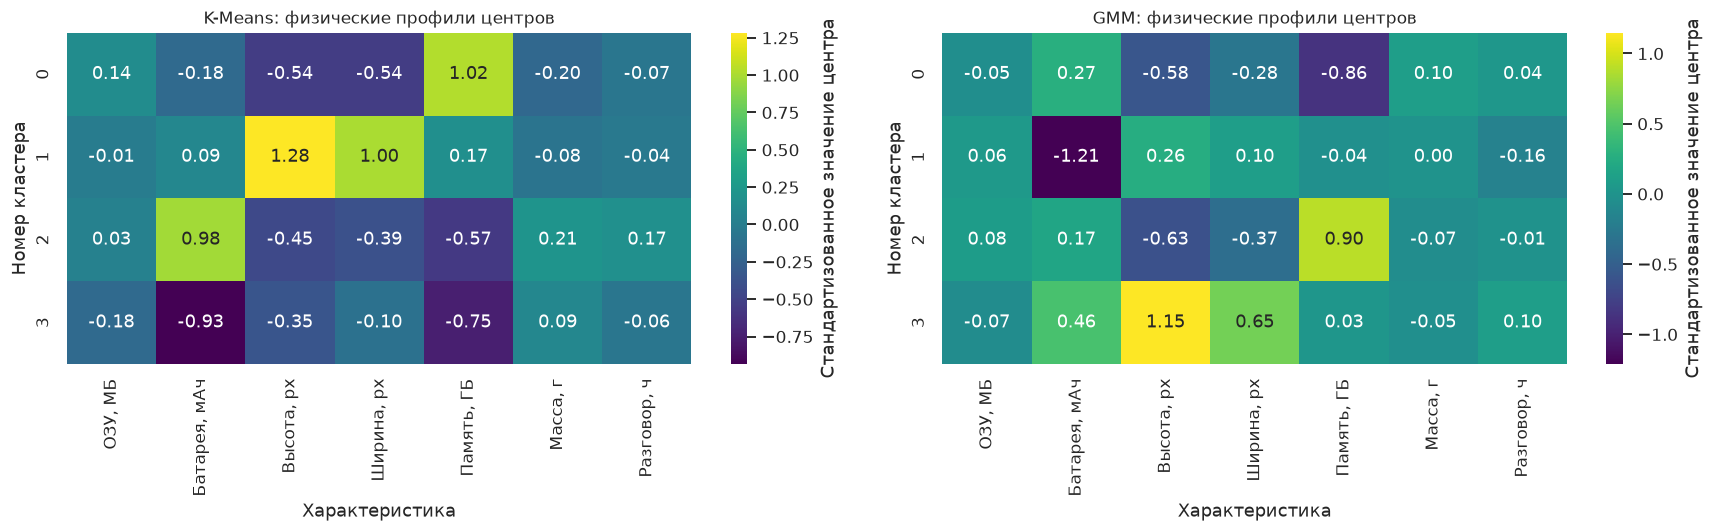

In [23]:
physical_profiles = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
unit_names = ['ОЗУ, МБ', 'Батарея, мАч', 'Высота, px', 'Ширина, px', 'Память, ГБ', 'Масса, г', 'Разговор, ч']
for ax, name in zip(axes, ['K-Means', 'GMM']):
    physical = pd.DataFrame(scaler.inverse_transform(centers[name]), columns=features).rename_axis('кластер')
    physical_profiles[name] = physical
    display(physical.rename(columns=dict(zip(features, unit_names))))
    sns.heatmap(pd.DataFrame(centers[name], columns=unit_names), annot=True, fmt='.2f', cmap='viridis',
                ax=ax, cbar_kws={'label': 'Стандартизованное значение центра'})
    ax.set(title=f'{name}: физические профили центров', xlabel='Характеристика', ylabel='Номер кластера')
plt.tight_layout(); plt.show()
agreement = adjusted_rand_score(labels_by_model['K-Means'], labels_by_model['GMM'])

physical_paragraphs = []
for method, physical in physical_profiles.items():
    lines = []
    for cluster, row in physical.iterrows():
        count = int((labels_by_model[method] == cluster).sum())
        zcenter = centers[method][cluster]
        leading = np.argsort(np.abs(zcenter))[-2:][::-1]
        signature = ', '.join(f'{unit_names[j]} {zcenter[j]:+.2f}σ' for j in leading)
        lines.append(f'- **Кластер {cluster}, {count} устройств.** ОЗУ {row.ram:.0f} МБ, '
            f'батарея {row.battery_power:.0f} мАч, экран {row.px_width:.0f}×{row.px_height:.0f} px, '
            f'накопитель {row.int_memory:.1f} ГБ, масса {row.mobile_wt:.1f} г, '
            f'разговор {row.talk_time:.1f} ч. Сильнее всего от среднего отличаются: {signature}.')
    physical_paragraphs.append(f'**{method}**\n\n' + '\n'.join(lines))
agreement = adjusted_rand_score(labels_by_model['K-Means'], labels_by_model['GMM'])
ram_spread = np.ptp(physical_profiles['K-Means'].ram)
analysis['profiles'] = ('### Пояснение к физическим портретам центров\n\n'
    'Таблицы возвращают центры из стандартной шкалы в МБ, мАч, пиксели, гигабайты, '
    'граммы и часы. Цветовая карта показывает отклонение от среднего в σ: положительные '
    'ячейки выше среднего, отрицательные ниже. Портреты читаются по реальным сочетаниям характеристик.\n\n'
    + '\n\n'.join(physical_paragraphs)
    + f'\n\nУ K-Means разброс ОЗУ между центрами всего {ram_spread:.0f} МБ. '
    'По карте заметнее различия экрана, батареи и встроенной памяти, поэтому группы '
    'разумнее описывать как технические сочетания, а не выстраивать по лестнице '
    '«ультрабюджетный — флагман». Эта лестница требовала бы отделения по характеристикам '
    'и подтверждения внешними метриками.\n\n'
    f'ARI между разбиениями двух методов равен {agreement:.4f}: это согласие самих '
    'методов, не совпадение с ценой. Центры GMM — средние мягких компонент; число устройств '
    'в списке получено жёстким выбором максимальной вероятности. Обратное масштабирование '
    'не отменяет предыдущую винзоризацию.')

### Пояснение к физическим портретам центров

Таблицы возвращают центры из стандартной шкалы в МБ, мАч, пиксели, гигабайты, граммы и часы. Цветовая карта показывает отклонение от среднего в σ: положительные ячейки выше среднего, отрицательные ниже. Портреты читаются по реальным сочетаниям характеристик.

**K-Means**

- **Кластер 0, 527 устройств.** ОЗУ 2272 МБ, батарея 1162 мАч, экран 1019×405 px, накопитель 50.6 ГБ, масса 133.3 г, разговор 10.6 ч. Сильнее всего от среднего отличаются: Память, ГБ +1.02σ, Высота, px -0.54σ.
- **Кластер 1, 520 устройств.** ОЗУ 2112 МБ, батарея 1278 мАч, экран 1684×1211 px, накопитель 35.1 ГБ, масса 137.5 г, разговор 10.8 ч. Сильнее всего от среднего отличаются: Высота, px +1.28σ, Ширина, px +1.00σ.
- **Кластер 2, 488 устройств.** ОЗУ 2158 МБ, батарея 1669 мАч, экран 1084×447 px, накопитель 21.7 ГБ, масса 147.7 г, разговор 12.0 ч. Сильнее всего от среднего отличаются: Батарея, мАч +0.98σ, Память, ГБ -0.57σ.
- **Кластер 3, 465 устройств.** ОЗУ 1934 МБ, батарея 828 мАч, экран 1207×490 px, накопитель 18.4 ГБ, масса 143.4 г, разговор 10.7 ч. Сильнее всего от среднего отличаются: Батарея, мАч -0.93σ, Память, ГБ -0.75σ.

**GMM**

- **Кластер 0, 556 устройств.** ОЗУ 2066 МБ, батарея 1359 мАч, экран 1129×389 px, накопитель 16.4 ГБ, масса 143.9 г, разговор 11.2 ч. Сильнее всего от среднего отличаются: Память, ГБ -0.86σ, Высота, px -0.58σ.
- **Кластер 1, 423 устройств.** ОЗУ 2186 МБ, батарея 706 мАч, экран 1297×760 px, накопитель 31.4 ГБ, масса 140.3 г, разговор 10.1 ч. Сильнее всего от среднего отличаются: Батарея, мАч -1.21σ, Высота, px +0.26σ.
- **Кластер 2, 543 устройств.** ОЗУ 2211 МБ, батарея 1315 мАч, экран 1091×366 px, накопитель 48.4 ГБ, масса 137.9 г, разговор 10.9 ч. Сильнее всего от среднего отличаются: Память, ГБ +0.90σ, Высота, px -0.63σ.
- **Кластер 3, 478 устройств.** ОЗУ 2046 МБ, батарея 1441 мАч, экран 1532×1151 px, накопитель 32.5 ГБ, масса 138.6 г, разговор 11.6 ч. Сильнее всего от среднего отличаются: Высота, px +1.15σ, Ширина, px +0.65σ.

У K-Means разброс ОЗУ между центрами всего 338 МБ. По карте заметнее различия экрана, батареи и встроенной памяти, поэтому группы разумнее описывать как технические сочетания, а не выстраивать по лестнице «ультрабюджетный — флагман». Эта лестница требовала бы отделения по характеристикам и подтверждения внешними метриками.

ARI между разбиениями двух методов равен 0.3607: это согласие самих методов, не совпадение с ценой. Центры GMM — средние мягких компонент; число устройств в списке получено жёстким выбором максимальной вероятности. Обратное масштабирование не отменяет предыдущую винзоризацию.

### Сравнительный анализ методов

,силуэт,CH,DB,ARI,RI,Jaccard macro,NMI,Homogeneity,Completeness,V-measure,WCSS,BIC
метод,,,,,,,,,,,,
K-Means,0.1144,256.3297,2.0959,0.0207,0.6328,0.1865,0.0266,0.0266,0.0266,0.0266,10106.382,NaN
GMM,0.0910,208.3572,2.3067,0.0086,0.6272,0.1714,0.0117,0.0116,0.0117,0.0117,NaN,39079.434


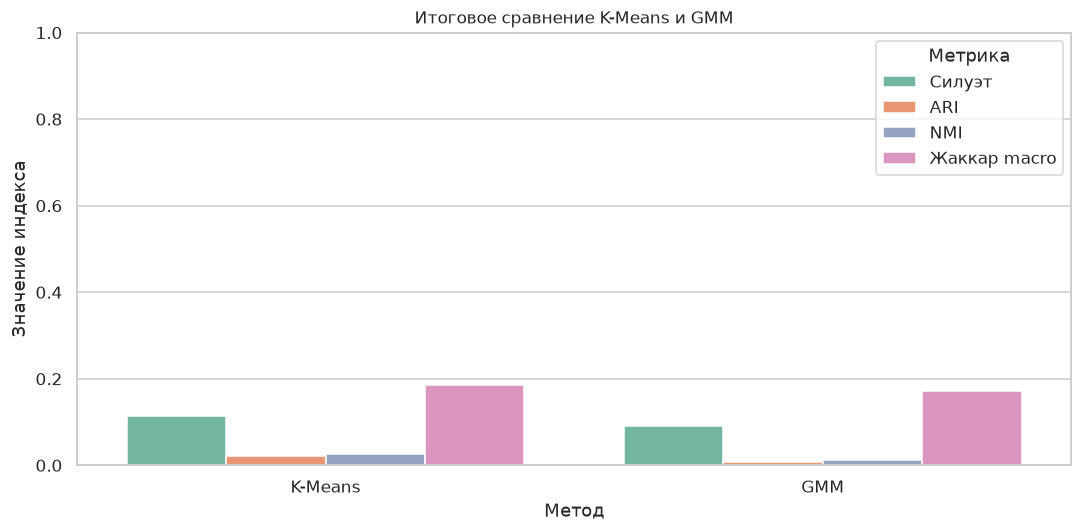

In [24]:
display(metrics.round(4))
comparison = metrics[['силуэт', 'ARI', 'NMI', 'Jaccard macro']].rename(
    columns={'силуэт': 'Силуэт', 'Jaccard macro': 'Жаккар macro'})
comparison_plot = comparison.rename_axis('Метод').reset_index().melt(
    id_vars='Метод', var_name='Метрика', value_name='Значение')
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=comparison_plot, x='Метод', y='Значение', hue='Метрика',
            palette='Set2', ax=ax)
ax.set(title='Итоговое сравнение K-Means и GMM', xlabel='Метод', ylabel='Значение индекса')
ax.set_ylim(0, 1)
ax.legend(title='Метрика')
plt.tight_layout(); plt.show()

comparison_lines = [f'- **{name}:** силуэт {row["силуэт"]:.4f}, ARI {row.ARI:.4f}, '
                    f'NMI {row.NMI:.4f}, Жаккар macro {row["Jaccard macro"]:.4f}, DB {row.DB:.4f}.'
                    for name, row in metrics.iterrows()]
analysis['comparison'] = ('### Пояснение к итоговому сравнению\n\n'
    'Столбцы показывают четыре индекса с направлением «больше — лучше» на одной '
    'выборке и в одном пространстве. Davies–Bouldin оставлен в таблице, потому что '
    'у него лучше меньшее значение. Высота разных метрик не сравнивается как одна единица качества.\n\n'
    + '\n'.join(comparison_lines)
    + '\n\nK-Means здесь лучше отделяет собственные технические группы, однако у обоих '
    'методов ARI и NMI малы. Совпадение RI выше 0.6 не означает восстановление цен: '
    'значительную часть согласия дают пары устройств из разных групп. Для выбранных '
    'характеристик и k=4 уверенно говорить о четырёх ценовых сегментах нельзя. '
    'Технические портреты найденных групп не следует отождествлять с ценовыми категориями.')

### Пояснение к итоговому сравнению

Столбцы показывают четыре индекса с направлением «больше — лучше» на одной выборке и в одном пространстве. Davies–Bouldin оставлен в таблице, потому что у него лучше меньшее значение. Высота разных метрик не сравнивается как одна единица качества.

- **K-Means:** силуэт 0.1144, ARI 0.0207, NMI 0.0266, Жаккар macro 0.1865, DB 2.0959.
- **GMM:** силуэт 0.0910, ARI 0.0086, NMI 0.0117, Жаккар macro 0.1714, DB 2.3067.

K-Means здесь лучше отделяет собственные технические группы, однако у обоих методов ARI и NMI малы. Совпадение RI выше 0.6 не означает восстановление цен: значительную часть согласия дают пары устройств из разных групп. Для выбранных характеристик и k=4 уверенно говорить о четырёх ценовых сегментах нельзя. Технические портреты найденных групп не следует отождествлять с ценовыми категориями.

## 6. Заключение
1. **Данные.** 2000 смартфонов, 20 характеристик; пропусков 0, дубликатов 0. Цена изолирована от обучения.
2. **Распределения.** Нормальность отвергнута у 14 из 14 небинарных признаков; это ограничивает интерпретацию смеси, но не запрещает кластеризацию.
3. **Предобработка.** Выбрано семь аппаратных характеристик. IQR-флаги есть у 20 устройств; изменения выбранных столбцов: {'px_height': 39}. Строки сохранены, расстояния стандартизованы.
4. **Кластерная тенденция.** Hopkins=0.9067 со степенью d и 0.5329 без неё; uniform-контроль в среднем 0.5002. Отклонение от равномерности не доказывает четыре отдельные группы.
5. **Число групп.** Максимум силуэта при k=2, эвристика локтя даёт k=5. Четыре группы сохранены как заранее заданный сценарий, а не объявлены оптимумом.
6. **Методы.** K-Means: силуэт 0.1144, ARI 0.0207; GMM: силуэт 0.0910, ARI 0.0086. Ценовые классы восстановлены слабо.
7. **Параметры.** Проверено 66 конфигураций K-Means, четыре ковариации GMM и 24 режима DBSCAN. Параметры не выбирались по ARI.
8. **Портреты.** Две компоненты PCA сохраняют 36.66% дисперсии. Группы различаются сочетаниями экрана, батареи и памяти; произвольные номера нельзя превратить в рыночные классы без подтверждения.
9. **Итог.** Техническая сегментация в этом сценарии не повторяет четыре цены. Для практического применения нужны новые устройства и проверка устойчивости к составу выборки; подстраивать признаки по скрытому эталону в этой работе нельзя.

## 7. Список источников
1. Mobile Price Classification / Abhishek Sharma // Kaggle : набор данных. URL: https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification (дата обращения: 09.11.2026; загрузка через kagglehub).
2. Scikit-learn. Clustering : документация [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/clustering.html.
3. MacQueen J. Some Methods for Classification and Analysis of Multivariate Observations // Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability. 1967. Vol. 1. P. 281–297.
4. Dempster A. P., Laird N. M., Rubin D. B. Maximum Likelihood from Incomplete Data via the EM Algorithm // Journal of the Royal Statistical Society. Series B. 1977. Vol. 39, no. 1. P. 1–38.
5. Hopkins B., Skellam J. G. A New Method for Determining the Type of Distribution of Plant Individuals // Annals of Botany. 1954. Vol. 18, no. 2. P. 213–227.
6. Rousseeuw P. J. Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis // Journal of Computational and Applied Mathematics. 1987. Vol. 20. P. 53–65.

## Приложение. Программное окружение и воспроизводимость

In [25]:
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__, 'seaborn': sns.__version__}
display(pd.Series(versions, name='Версия'))

analysis['environment'] = ('### Пояснение к воспроизводимости\n\n'
    + '; '.join(f'{k} {v}' for k, v in versions.items())
    + f'. Зафиксированы RANDOM_STATE={RANDOM_STATE}, состав семи признаков и одни и те же '
    f'{len(X)} строк во всех основных сравнениях. Полный листинг встроен в ячейки; '
    'ноутбук выполняется сверху вниз в чистом ядре без соседних Python-файлов.\n\n'
    'Kaggle нужен для первоначального получения train.csv; далее доступен локальный кэш. '
    'Версии зависимостей закреплены в requirements-lock.txt. Для повторения расчётов '
    'необходимо выполнить все ячейки по порядку в чистом ядре с указанными версиями '
    'пакетов. При изменении данных или параметров численные выводы нужно проверить заново.')
analysis['conclusion'] = (
    f'1. **Данные.** {len(X_raw)} смартфонов, {X_raw.shape[1]} характеристик; пропусков '
    f'{missing}, дубликатов {duplicates}. Цена изолирована от обучения.\n'
    f'2. **Распределения.** Нормальность отвергнута у {rejected} из {len(continuous)} '
    'небинарных признаков; это ограничивает интерпретацию смеси, но не запрещает кластеризацию.\n'
    f'3. **Предобработка.** Выбрано семь аппаратных характеристик. IQR-флаги есть у '
    f'{int(iqr_flags.any(axis=1).sum())} устройств; изменения выбранных столбцов: {clipped}. '
    'Строки сохранены, расстояния стандартизованы.\n'
    f'4. **Кластерная тенденция.** Hopkins={h_observed:.4f} со степенью d и '
    f'{h_linear:.4f} без неё; uniform-контроль в среднем {np.mean(null_values):.4f}. '
    'Отклонение от равномерности не доказывает четыре отдельные группы.\n'
    f'5. **Число групп.** Максимум силуэта при k={best_k}, эвристика локтя даёт '
    f'k={elbow_k}. Четыре группы сохранены как заранее заданный сценарий, а не объявлены оптимумом.\n'
    f'6. **Методы.** K-Means: силуэт {metrics.loc["K-Means", "силуэт"]:.4f}, '
    f'ARI {metrics.loc["K-Means", "ARI"]:.4f}; GMM: силуэт {metrics.loc["GMM", "силуэт"]:.4f}, '
    f'ARI {metrics.loc["GMM", "ARI"]:.4f}. Ценовые классы восстановлены слабо.\n'
    f'7. **Параметры.** Проверено {len(parameters)} конфигураций K-Means, четыре '
    f'ковариации GMM и {len(db_table)} режима DBSCAN. Параметры не выбирались по ARI.\n'
    f'8. **Портреты.** Две компоненты PCA сохраняют {pca.explained_variance_ratio_.sum():.2%} '
    'дисперсии. Группы различаются сочетаниями экрана, батареи и памяти; произвольные '
    'номера нельзя превратить в рыночные классы без подтверждения.\n'
    '9. **Итог.** Техническая сегментация в этом сценарии не повторяет четыре цены. '
    'Для практического применения нужны новые устройства и проверка устойчивости '
    'к составу выборки; подстраивать признаки по скрытому эталону в этой работе нельзя.')

python          3.13.2
numpy            2.5.4
pandas           3.1.1
scipy           1.18.1
scikit-learn     1.9.1
seaborn         0.13.2
Name: Версия, dtype: str

### Пояснение к воспроизводимости

python 3.13.2; numpy 2.5.4; pandas 3.1.1; scipy 1.18.1; scikit-learn 1.9.1; seaborn 0.13.2. Зафиксированы RANDOM_STATE=42, состав семи признаков и одни и те же 2000 строк во всех основных сравнениях. Полный листинг встроен в ячейки; ноутбук выполняется сверху вниз в чистом ядре без соседних Python-файлов.

Kaggle нужен для первоначального получения train.csv; далее доступен локальный кэш. Версии зависимостей закреплены в requirements-lock.txt. Для повторения расчётов необходимо выполнить все ячейки по порядку в чистом ядре с указанными версиями пакетов. При изменении данных или параметров численные выводы нужно проверить заново.